# Perfume Market Intelligence

## Project Overview

This analysis examines a perfume company's product, sales, revenue, pricing, brand and inventory data. The dataset contains **1,998 perfume listings across 17 columns**.

The objective is to understand the market, identify the main drivers of performance, highlight inventory risks and translate the findings into practical business actions.

The analysis follows a clear business path:

**Clean the data → Understand the market → Identify performance drivers → Examine price and sales → Translate findings into inventory actions**

### Key Business Questions

The analysis is organised into four sections and 11 business questions:

**Market Overview**
1. What does the product mix look like?
2. Which price segments generate the most revenue?
3. Which brands sell the most units?
4. Does brand popularity relate to revenue performance?

**Market Drivers**
5. Which brands have the highest inventory risk?
6. How concentrated is revenue across countries?
7. How do men's and women's products compare?
8. What drives the gender revenue gap?

**Price & Sales**
9. Does a higher price mean lower sales?
10. Which price range performs best?

**Inventory & Action**
11. Where are the inventory risks and opportunities?

The conclusions are based only on the information available in the dataset. Where the data cannot confirm a business decision, the finding is presented as an area for further investigation rather than a definite conclusion.


## Step 1: Load and Inspect the Data


In [163]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker

### Visual Setup

A consistent colour palette and chart style are applied throughout the analysis. This keeps the visuals easy to compare and gives the notebook a clear, professional appearance.


In [164]:
# Color palette
BLUE_1 = '#DCEBFC'
BLUE_2 = '#B3D4F7'
BLUE_3 = '#7FB8F0'
BLUE_4 = '#4B9CE8'
BLUE_5 = '#2E86DE'
BLUE_6 = '#1D6FC0'
BLUE_7 = '#155A9C'
BLUE_8 = '#0D3D6B'

GREY = '#7A7A7A'
BLACK = '#000000'
WHITE = '#FFFFFF'

colors = [BLUE_1, BLUE_2, BLUE_3, BLUE_4, BLUE_5, BLUE_6, BLUE_7, BLUE_8, GREY]

GENDER_COLORS = {'Men': BLUE_5, 'Women': BLUE_8}

PRICE_ORDER = ['Budget', 'Mid-Range', 'Luxury']
PRICE_COLORS = {'Budget': BLUE_4, 'Mid-Range': BLUE_6, 'Luxury': BLUE_8}

SEGMENT_ORDER = ['Mass Market', 'Premium', 'Luxury']
SEGMENT_COLORS = {'Mass Market': BLUE_3, 'Premium': BLUE_6, 'Luxury': BLUE_8}

PERF_ORDER = ['Low Seller', 'Medium Seller', 'High Seller']
PERF_COLORS = {'Low Seller': BLUE_4, 'Medium Seller': BLUE_5, 'High Seller': BLUE_7}

# Chart style
sns.set_theme(style='white')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'figure.dpi': 110
})

def style_axis(ax, title, xlabel='', ylabel=''):
    ax.set_title(title, loc='left', color='#2E2E2E')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return ax


### Loading and Inspecting the Dataset

The dataset is loaded first, followed by a review of its rows, columns and available fields. This establishes the structure of the data before any cleaning or analysis begins.


In [ ]:
df = pd.read_csv('data/Perfume_Market_Intelligence_Dataset.csv')

In [166]:
df

,Brand,Product,Gender,Product_Type,Price,Sold,Available,Revenue_Potential,Demand_Score,Price_Category,Market_Segment,Sales_Performance,Brand_Popularity,Country,Inventory_Status,Stock_Turnover,Revenue_Rank
0,Paco Rabanne,Paco Rabanne Invictus 3.4 oz EDT Sporty Men's ...,Men,EDT,39.99,118.0,10.0,4718.82,94.597,Mid-Range,Premium,High Seller,High,United States,Medium Stock,Fast,Others
1,Lucianno,Lucianno California Vibe M 100ml Boxed,Men,Unknown,66.00,21.0,10.0,1386.00,34.500,Mid-Range,Premium,Medium Seller,Low,Canada,Medium Stock,Slow,Others
2,BHARARA,BHARARA KING PURE PARFUM BY BHARARA 3.4 FOR ME...,Men,Parfum,71.49,31.0,4.0,2216.19,43.147,Mid-Range,Premium,Medium Seller,Low,United States,Low Stock,Fast,Others
3,Branded,*Perfume Para Hombre Con Feromonas De Atraer M...,Men,Unknown,17.99,1.0,13.0,17.99,6.097,Budget,Mass Market,Low Seller,Low,United States,Medium Stock,Slow,Others
4,Thierry Mugler,Alien by Thierry Mugler 3 oz EDP Perfume for W...,Women,EDP,85.56,953.0,0.0,81538.68,692.768,Luxury,Luxury,High Seller,Medium,United States,Low Stock,Fast,Top 10%
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1993,Kilian,Kilian Angels' Share Eau De Parfum Sample Spra...,Women,Parfum,7.99,333.0,10.0,2660.67,235.497,Budget,Mass Market,High Seller,Medium,United States,Medium Stock,Fast,Others
1994,Marc Jacobs,Marc Jacobs Daisy Wild Eau De Parfum EDP Minia...,Women,EDP,28.99,3.0,7.0,86.97,10.797,Budget,Mass Market,Low Seller,Medium,United States,Medium Stock,Slow,Others
1995,Maison Francis Kurkdjian,Maison Francis Kurkdjian Amyris Pour Homme Eau...,Men,Eau De Toilette,159.99,2.0,4.0,319.98,49.397,Luxury,Luxury,Low Seller,Low,United States,Low Stock,Slow,Others
1996,Burberry,Burberry Touch by Burberry perfume for women E...,Women,EDP,34.93,1947.0,0.0,68008.71,1373.379,Mid-Range,Premium,High Seller,High,United States,Low Stock,Fast,Top 10%


## Understanding the Dataset Columns

The dataset contains information covering the **products, pricing, sales, revenue, market segments, brands, and inventory status** of the perfume listings.

To make the analysis easier to follow, the main columns are described below. These definitions explain what each field represents and how it is used throughout the analysis.

| **Column** | **Description** |
|---|---|
| **Brand** | The brand associated with the perfume product. |
| **Product** | The name or description of the perfume listing. |
| **Gender** | The target gender category of the product, such as Men or Women. |
| **Type** | The type of fragrance, such as EDP, EDT, Parfum, or Cologne. |
| **Price** | The selling price of the perfume product. |
| **Sold** | The number of units sold for the product. |
| **Available** | The number of units currently available in stock. |
| **Revenue** | The sales value generated from the products sold, calculated as **Price × Units Sold**. |
| **Price Category** | Groups products into **Budget, Mid-Range, or Luxury** based on their price. |
| **Market Segment** | Groups products into **Mass Market, Premium, or Luxury** based on their market positioning. |
| **Sales Performance** | Classifies products according to their sales level, such as Low Seller, Medium Seller, or High Seller. |
| **Brand Popularity** | Indicates the relative popularity of a brand based on its sales performance. |
| **Country** | The country associated with the product listing. |
| **Inventory Status** | Indicates the current stock level of a product, such as Low Stock, Medium Stock, or High Stock. |
| **Stock Turnover** | Indicates how quickly available inventory is being sold. |
| **Revenue Rank** | Shows the relative position of a product based on its revenue. |

**Checking the Data Structure**

`df.info()` provides an overview of the column names, number of populated values and data types. This helps identify missing information and confirm that numeric and text fields are stored appropriately.


In [167]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1998 entries, 0 to 1997
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Brand              1996 non-null   str    
 1   Product            1998 non-null   str    
 2   Gender             1998 non-null   str    
 3   Product_Type       1998 non-null   str    
 4   Price              1998 non-null   float64
 5   Sold               1998 non-null   float64
 6   Available          1998 non-null   float64
 7   Revenue_Potential  1998 non-null   float64
 8   Demand_Score       1998 non-null   float64
 9   Price_Category     1998 non-null   str    
 10  Market_Segment     1998 non-null   str    
 11  Sales_Performance  1998 non-null   str    
 12  Brand_Popularity   1998 non-null   str    
 13  Country            1998 non-null   str    
 14  Inventory_Status   1998 non-null   str    
 15  Stock_Turnover     1998 non-null   str    
 16  Revenue_Rank       1998 non-null   

**Result:** The dataset contains 17 columns. Price and sales-related fields are stored as numbers, while the category fields are stored as text.

The `Brand` column has 2 missing values. All other columns are complete.


### Cleaning the Data

Before analysing the market, the dataset is checked for common data-quality issues:

- Duplicate records
- Missing values
- Different spellings or labels
- Inconsistent formatting
- Incorrect or unclear categories

Clear errors are corrected and labels are standardised while valid information is retained.


In [168]:
df.duplicated().sum()

np.int64(0)

### Checking for Missing Values

Each column is checked for missing values to identify any gaps that could affect the analysis.


In [169]:
df.isna().sum()

Brand                2
Product              0
Gender               0
Product_Type         0
Price                0
Sold                 0
Available            0
Revenue_Potential    0
Demand_Score         0
Price_Category       0
Market_Segment       0
Sales_Performance    0
Brand_Popularity     0
Country              0
Inventory_Status     0
Stock_Turnover       0
Revenue_Rank         0
dtype: int64

**Result:** Only the `Brand` column has missing values, with 2 missing entries out of 1,998 rows. All other columns are complete.


### Filling the 2 Missing Brand Names

The product titles for the two rows with missing brands are reviewed. Both titles clearly contain the name **Versace**, allowing the missing brand values to be recovered from the available information without guessing.


In [170]:
missing = df[df['Brand'].isna()]
missing

,Brand,Product,Gender,Product_Type,Price,Sold,Available,Revenue_Potential,Demand_Score,Price_Category,Market_Segment,Sales_Performance,Brand_Popularity,Country,Inventory_Status,Stock_Turnover,Revenue_Rank
438,NaN,Versace Pour Homme Oud Noir 3.4 oz EDP Cologne...,Men,EDP,55.16,3110.0,0.0,171547.6,2193.548,Mid-Range,Premium,High Seller,Low,United States,Low Stock,Fast,Top 10%
943,NaN,Bright Crystal de Versace Eau de Toilette 3.0 ...,Women,Eau De Toilette,29.99,0.0,0.0,0.0,8.997,Budget,Mass Market,Low Seller,Low,Estados Unidos,Low Stock,Fast,Others


**Result:** Both missing brand values were filled as **Versace**.


In [171]:

df.loc[df['Brand'].isna() & df['Product'].str.contains('Versace', case=False), 'Brand'] = 'Versace'

### Standardizing Brand Names

Brand values are reviewed for differences in spelling, spacing, capitalization and naming. Standardising these values ensures that the same brand is not counted as multiple brands during the analysis.


In [172]:
df['Brand'].nunique()

401

The full list of brand values is reviewed to identify clear duplicates, spelling errors, non-brand descriptions and different names referring to the same brand.


In [173]:
for brand in sorted(df['Brand'].unique()):
    print(brand)

2nd To None
AERIN
ALFRED SUNG
ALT Fragrances
AS  SHOWN
AS PHOTOS
AS PICTURE SHOWN
AS SHOW
AS SHOWN
ASST
AXE
Abercrombie & Fitch
Acqua Di Gio
Acqua di Parma
Adam Levine
Aeropostale
Afnan
Ainash Perfums
Al Haramain
Al Rehab
Al Wataniah
Al-Rehab
Alexandria Fragrances
Alfred Sung
Allsaints
Amouage
Anna Sui
Aquolina
Arabian Oud
Aramis
Ard Al Zaafaran
Ariana Grande
Armaf
Armand Dupree Fuller
As Picture Show
As Picture Shown
As Show
As Shown
As picture show
As shown
Assorted
Atelier Cologne
Atlantic
Avon
Azzaro
BHARARA
BOD man
BRUT
BURBERRY
BYREDO
Baby Phat
Banana Republic
Baron
Bath & Body Works
Bellie Eilish
Benetton
Bentley
Bharara
Blue Perfumes
Bond No. 9
Boucheron
Branded
Britney Spears
Brut
Burberry
Bvlgari
By Al Hambra
Byredo
C.K
CHANEL
CHANGE For Women
CHRISTIAN DIOR
CURVE
Cacharel
Calvin Klein
Carolina Herrera
Cartier
Chaka by Chaka Khan
Chanel
Chloe
Chloé
Chopard
Christian Audigier
Christian Dior
Classic Brands
Classic Erotica
Claude Marsal
Clean
Clinique
Clive Christian
Clubman Pin

**Result:** There were 401 different brand values before cleaning.

The dataset contained differences in capitalization, unknown labels, spelling mistakes and alternate names for the same brand. These entries were reviewed individually, and brands were only merged where the match was clear.


**Step A: Standardize Capitalization and Spacing**

Capitalization and spacing are standardised so different versions of the same brand are grouped together.

For example, `versace`, `VERSACE` and `Versace` are treated as the same brand.


In [174]:
df['Brand'] = df['Brand'].str.strip().str.title()

**Step B: Label Non-Brand Entries as `Unknown`**

Some values, such as `As Shown` and `Generic`, describe the product rather than identify a specific brand. These values are classified as `Unknown`, while the records are retained because their price, sales and inventory information remains useful for the analysis.


In [175]:
not_a_brand_values = [
    'As Shown', 'As  Shown', 'As Show', 'As Showed', 'As Picture Show',
    'As Picture Shown', 'As Photos', 'See Photo', 'Does Not Apply', 'Generic',
    'Asst', 'Assorted', 'Branded', 'Luxury', 'Limited Edition', 'Designer Series',
    'Cologne', 'Parfum', 'Parfums', 'Perfume', 'Pheromones', 'Multiple Brands',
    'Preferred Fragrance', 'Fragrance','Unbranded'
]
df.loc[df['Brand'].isin(not_a_brand_values), 'Brand'] = 'Unknown'

In [176]:
df['Brand'].nunique()
print(f'Unique brand values after Steps A & B: {df["Brand"].nunique()}')

Unique brand values after Steps A & B: 348


**Step C: Merge Clear Misspellings and Alternate Names**

Similar brand names are reviewed and merged where the spelling difference or alternate name clearly refers to the same brand.


In [177]:
df.loc[df['Brand'].isin(['Dolce&Gabbana', 'Dolce Gabbana', '~ Dolce & Gabbana ~']), 'Brand'] = 'Dolce & Gabbana'
df.loc[df['Brand'].isin(['Giorgi^O Armani', 'Giorgio Arm.Ani', 'Giorgio² Armani']), 'Brand'] = 'Giorgio Armani'
df.loc[df['Brand'].isin(['Al Hambra', 'By Al Hambra']), 'Brand'] = 'Maison Alhambra'
df.loc[df['Brand'].isin(['Armand Dupree Fuller', 'Fuller Armand Dupree']), 'Brand'] = 'Armand Dupree Fuller'
df.loc[df['Brand'].isin(['Roja Dove', 'Roja Parfums']), 'Brand'] = 'Roja'
df.loc[df['Brand'].isin(['J Lo', 'Jennifer Lopez', 'Jlo']), 'Brand'] = 'Jlo'
df.loc[df['Brand'].isin(['Polo Ralph Lauren', 'Ralph Lauren','Polo']), 'Brand'] = 'Ralph Lauren'
df.loc[df['Brand'].isin(['Christian Dior', 'Dior']), 'Brand'] = 'Christian Dior'
df.loc[df['Brand'].isin(['Ysl', 'Yves Saint Laurent']), 'Brand'] = 'YSL'

In [178]:
df.loc[df['Brand'] == 'Tiffany', 'Brand'] = 'Tiffany & Co.'
df.loc[df['Brand'] == 'Mont Blanc', 'Brand'] = 'Montblanc'
df.loc[df['Brand'] == 'Mercedes-Benz', 'Brand'] = 'Mercedes Benz'
df.loc[df['Brand'] == 'Parfums Grès', 'Brand'] = 'Parfums Gres'
df.loc[df['Brand'] == 'Lattafa Perfumes', 'Brand'] = 'Lattafa'
df.loc[df['Brand'] == 'Mancera', 'Brand'] = 'Mancera Paris'

In [179]:
df.loc[df['Brand'] == 'Lancome', 'Brand'] = 'Lancôme'
df.loc[df['Brand'] == 'Al-Rehab', 'Brand'] = 'Al Rehab'
df.loc[df['Brand'] == 'Chloé', 'Brand'] = 'Chloe'
df.loc[df['Brand'] == 'Estée Lauder', 'Brand'] = 'Estee Lauder'
df.loc[df['Brand'] == 'Hermès', 'Brand'] = 'Hermes'
df.loc[df['Brand'] == 'Victor & Rolf', 'Brand'] = 'Viktor & Rolf'
df.loc[df['Brand'] == 'The Baron', 'Brand'] = 'Baron'

**Step D: Use a Consistent Final Format**

A consistent final format is applied to brand names so grouping, ranking and counting are not affected by formatting differences.


In [180]:
df['Brand'] = df['Brand'].str.strip().str.upper()

In [181]:
df['Brand'].nunique()
print(f'Final unique brand count: {df["Brand"].nunique()}')

Final unique brand count: 319


### Recovering More Brands from `Unknown` Rows

For records still classified as `Unknown`, the product title is checked for a clear brand name.

A brand is recovered only when exactly one known brand can be identified. If the brand is unclear or multiple brands could match, the value remains `Unknown` rather than introducing an unsupported assumption.


In [182]:
unknown_brands = df['Brand'].str.upper() == 'UNKNOWN'
unknown_brands_count = unknown_brands.sum()
unknown_brands_count

np.int64(157)

In [183]:
known_brands = df.loc[~unknown_brands, 'Brand'].dropna().unique()


In [184]:
known_brands = sorted(
    df.loc[~unknown_brands, 'Brand'].unique(),
    key=len,
    reverse=True
)

In [185]:
def find_single_brand(product_desc):
    product_lower = str(product_desc).lower()
    matches = [b for b in known_brands if b.lower() in product_lower]
    return matches[0] if len(matches) == 1 else None

In [186]:
recovered = df.loc[unknown_brands, 'Product'].fillna('').apply(find_single_brand)


In [187]:
df.loc[recovered.dropna().index, 'Brand'] = recovered.dropna()

In [188]:
recovered_count = recovered.dropna().shape[0]
remaining_unknowns_count = (df['Brand'].str.upper() == 'UNKNOWN').sum()

In [189]:
print(f'Brands recovered from product titles: {recovered_count}')
print(f'Rows still genuinely unknown: {remaining_unknowns_count}')
print(f'Final distinct brand count: {df["Brand"].nunique()}')

Brands recovered from product titles: 48
Rows still genuinely unknown: 109
Final distinct brand count: 319


### Checking the `Gender` Column

The `Gender` column is checked to confirm that it contains the expected categories and that invalid values will not affect the gender comparison.


In [190]:
df['Gender'].unique()

<ArrowStringArray>
['Men', 'Women']
Length: 2, dtype: str

### Standardizing Country Names

Country names are reviewed and standardised where clear spelling or naming differences refer to the same country. This ensures that country-level revenue is grouped correctly.


In [191]:
df['Country'].unique()

<ArrowStringArray>
[ 'United States',         'Canada',          'China',      'Hong Kong',
       'Pakistan',          'India',         'Taiwan',       'Portugal',
 'Estados Unidos',         'Poland',       'Bulgaria',          'Japan',
         'Israel',         'Brazil']
Length: 14, dtype: str

**Result:** `Estados Unidos` is the Spanish name for `United States`, so both were treated as the same country and merged under `United States`.


In [192]:
df['Country'] = df['Country'].replace({'Estados Unidos': 'United States'})
df['Country'].value_counts()

Country
United States    1833
Hong Kong         100
China              25
Canada             16
Taiwan             12
India               4
Poland              2
Pakistan            1
Portugal            1
Bulgaria            1
Japan               1
Israel              1
Brazil              1
Name: count, dtype: int64

### Standardizing Product-Type Labels

The `Product_Type` column is reviewed for different labels that represent the same fragrance type.


In [193]:
df['Product_Type'].unique()

<ArrowStringArray>
['EDT', 'Unknown', 'Parfum', 'EDP', 'Eau De Toilette', 'Cologne']
Length: 6, dtype: str

**Result:** The dataset used both `Eau De Toilette` and `EDT`. These refer to the same fragrance type, so both are standardised as **`EDT`**.


The affected records are checked first to confirm that both labels refer to the same product type before standardisation.


In [194]:
df[df['Product_Type'].isin(['EDT', 'Eau De Toilette'])][
    ['Product', 'Brand', 'Product_Type']
]

,Product,Brand,Product_Type
0,Paco Rabanne Invictus 3.4 oz EDT Sporty Men's ...,PACO RABANNE,EDT
6,Avon Black Suede for Men Eau De Toilette Spray...,AVON,Eau De Toilette
8,ETERNITY for Men by CALVIN KLEIN 3.3 / 3.4 oz ...,CALVIN KLEIN,EDT
15,Valentino Uomo Born In Roma Eau De Toilette Tr...,VALENTINO,Eau De Toilette
18,Burberry Her Blossom Eau De Toilette EDT Perfu...,BURBERRY,EDT
...,...,...,...
1975,Valentino Uomo Born In Roma Coral Fantasy 3.4 ...,VALENTINO,EDT
1980,"L'eau D'issey Intense by Issey Miyake, 2.5 oz ...",ISSEY MIYAKE,EDT
1988,Terre D'Hermes by Hermes cologne for men EDT 3...,HERMES,EDT
1995,Maison Francis Kurkdjian Amyris Pour Homme Eau...,MAISON FRANCIS KURKDJIAN,Eau De Toilette


The two labels are merged under `EDT`, followed by a check of the updated distribution to confirm the change.


In [195]:
df['Product_Type'] = df['Product_Type'].replace('Eau De Toilette', 'EDT')
print(df['Product_Type'].value_counts())

Product_Type
EDT        612
EDP        588
Parfum     411
Cologne    199
Unknown    188
Name: count, dtype: int64


### Checking the Remaining Category Columns

The following columns are also reviewed for spelling, capitalization and unexpected values:

- `Price_Category`
- `Market_Segment`
- `Sales_Performance`
- `Revenue_Rank`
- `Inventory_Status`
- `Brand_Popularity`
- `Stock_Turnover`


In [196]:
df['Price_Category'].unique()

<ArrowStringArray>
['Mid-Range', 'Budget', 'Luxury']
Length: 3, dtype: str

In [197]:
df['Market_Segment'].unique()

<ArrowStringArray>
['Premium', 'Mass Market', 'Luxury']
Length: 3, dtype: str

In [198]:
df['Sales_Performance'].unique()

<ArrowStringArray>
['High Seller', 'Medium Seller', 'Low Seller']
Length: 3, dtype: str

In [199]:
df['Revenue_Rank'].unique()

<ArrowStringArray>
['Others', 'Top 10%', 'Top 25%']
Length: 3, dtype: str

In [200]:
df['Inventory_Status'].unique()

<ArrowStringArray>
['Medium Stock', 'Low Stock', 'High Stock']
Length: 3, dtype: str

In [201]:
df['Brand_Popularity'].unique()

<ArrowStringArray>
['High', 'Low', 'Medium']
Length: 3, dtype: str

In [202]:
df['Stock_Turnover'].unique()

<ArrowStringArray>
['Fast', 'Slow', 'Moderate']
Length: 3, dtype: str

**Result:** All seven columns contain the expected categories. No further cleaning was needed for these fields.


In [203]:
df = df.rename(columns={"Revenue_Potential": "Revenue"})

### Statistical Summary

`df.describe()` is used to review the minimum, maximum and average values for the numeric columns. This provides a quick check of the overall range and distribution of the main measures.


In [204]:
df.describe().round(2)

,Price,Sold,Available,Revenue,Demand_Score
count,1998.00,1998.00,1998.00,1998.00,1998.00
mean,43.17,626.14,18.24,19868.33,451.25
std,32.63,2458.46,53.69,76914.45,1720.08
min,1.99,0.00,0.00,0.00,3.70
25%,21.96,14.00,3.00,511.32,24.62
50%,34.00,49.00,9.00,1811.52,51.60
75%,53.99,278.75,10.00,9446.99,207.02
max,299.99,54052.00,842.00,1420246.15,37843.57


**Result:** Prices, sales and stock levels contain no negative values. Some products have not sold yet, while others are currently out of stock. Products with zero sales also have zero `Revenue`.


## Step 2: Market Overview

With the data prepared, the analysis begins with the overall market. This section examines **the product mix, sales performance and main sources of revenue**.


### Dashboard

The dashboard provides a high-level view of the perfume market, covering products, brands, revenue, units sold, average price, gender, countries and inventory.


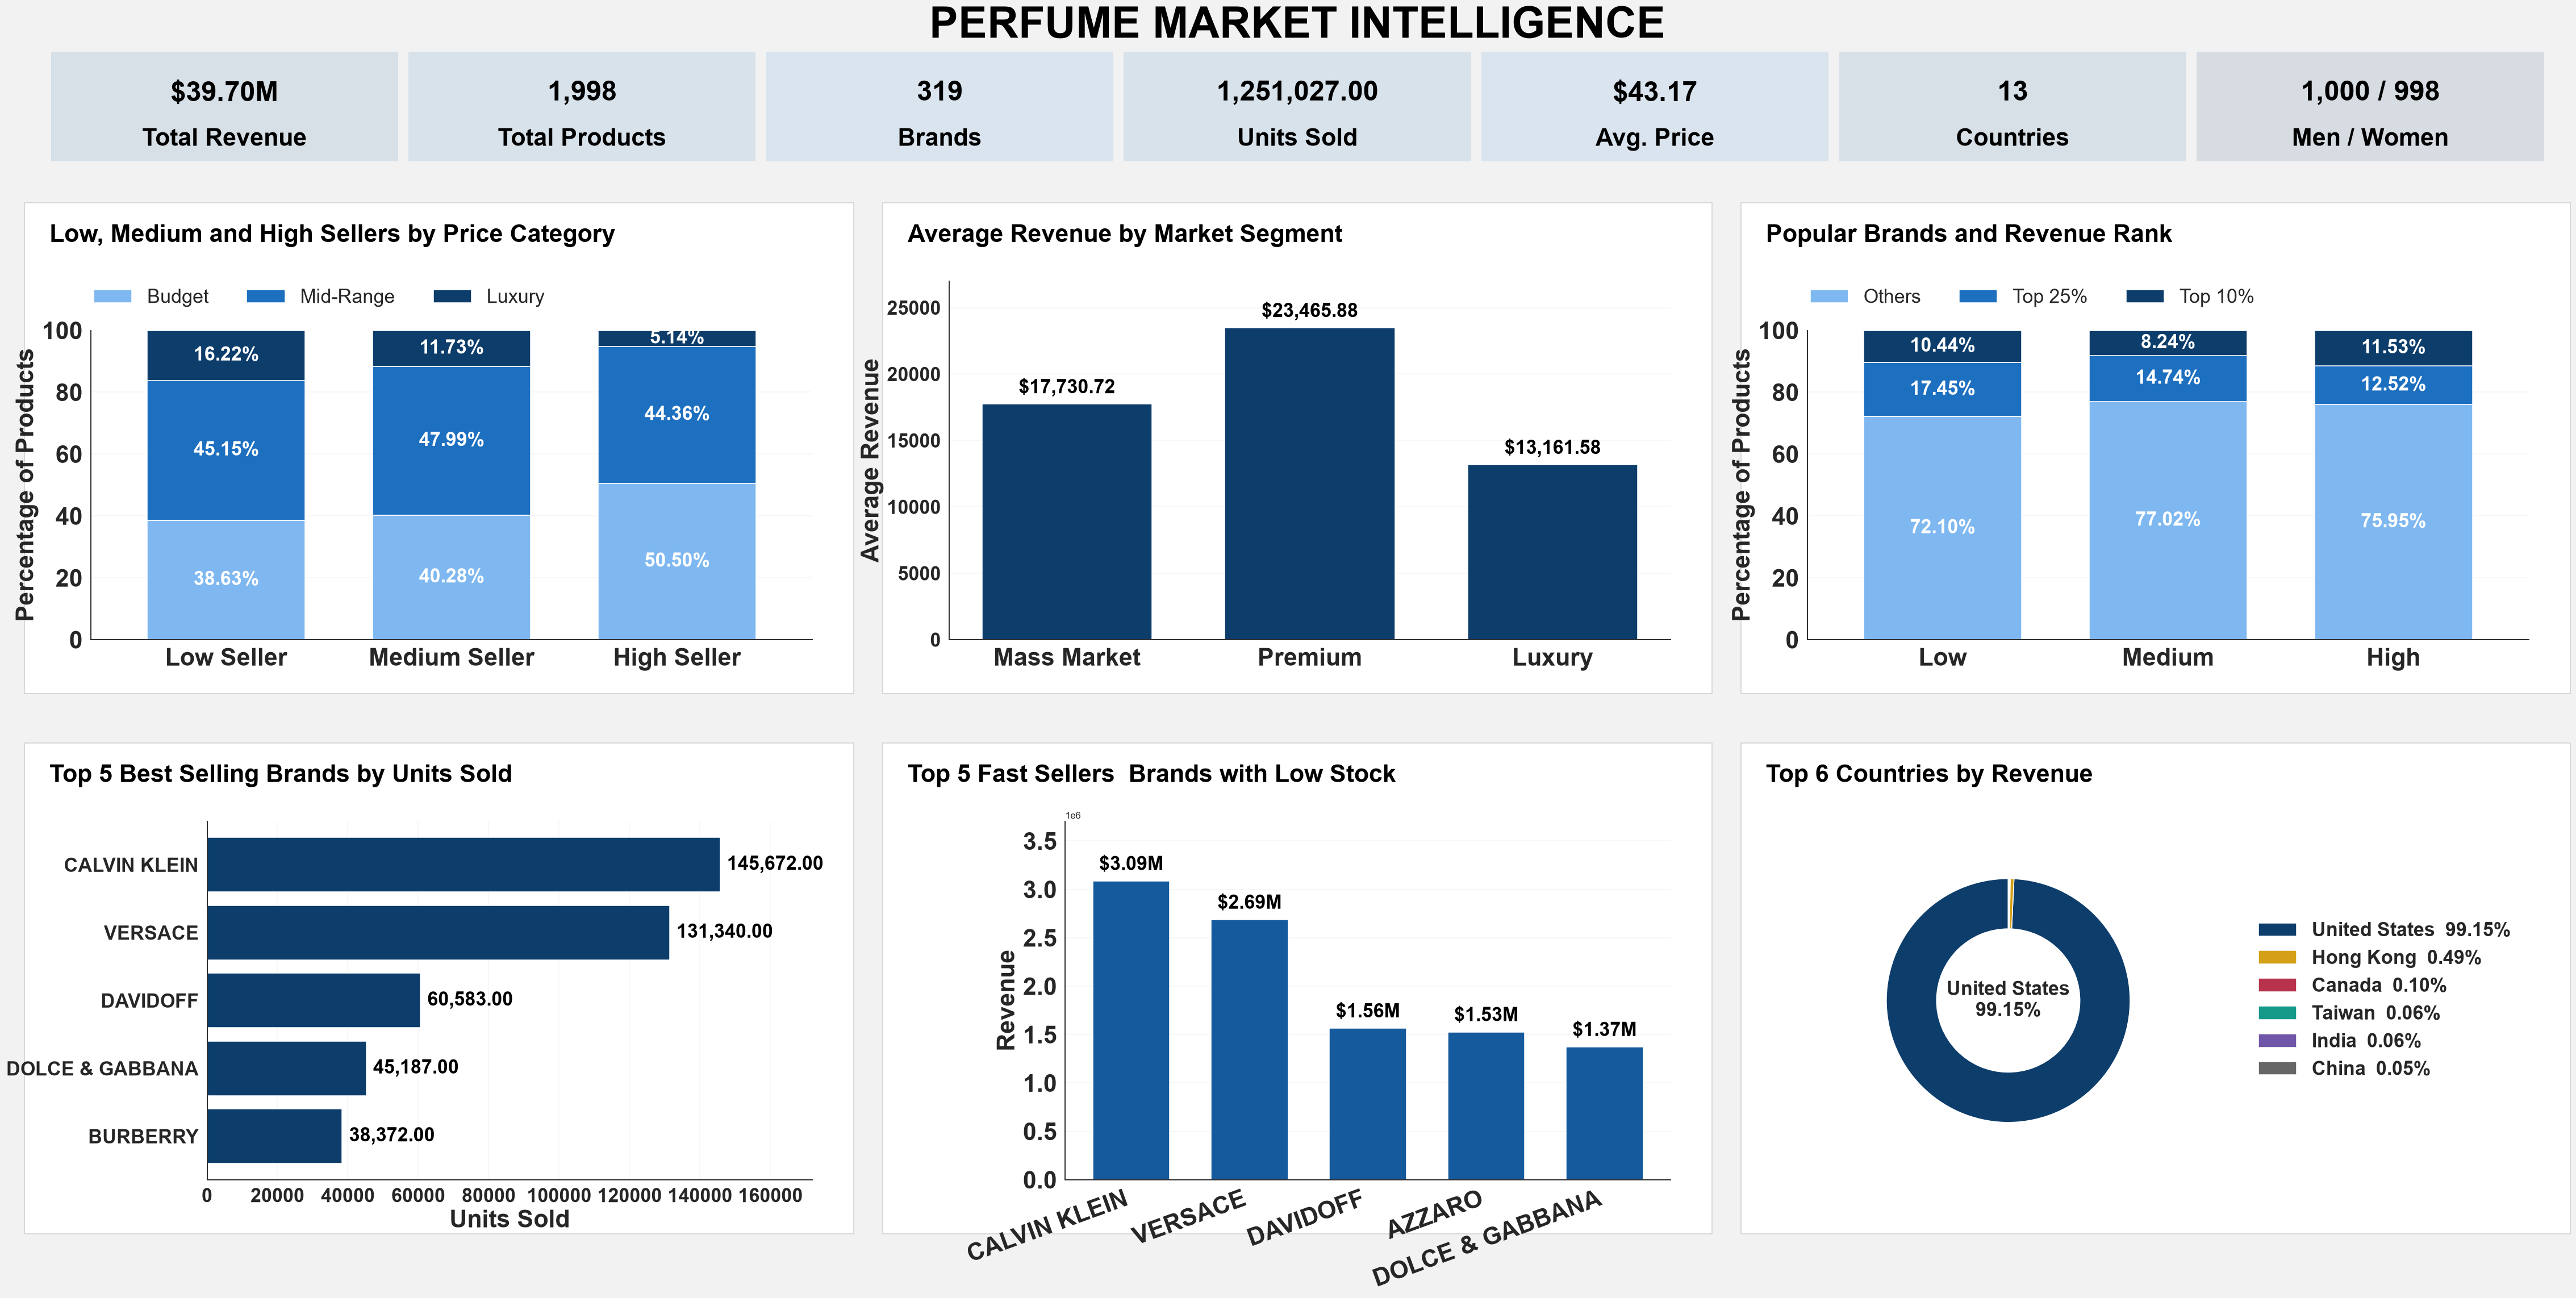

In [205]:
# Panel
def panel(fig, gs, row, col, title, left=0.08, legend=False):
    cell = gs[row, col].get_position(fig)
    x0, y0, w, h = cell.x0, cell.y0, cell.width, cell.height

    fig.add_artist(plt.Rectangle((x0, y0), w, h, transform=fig.transFigure,
                                 facecolor='white', edgecolor='#D0D0D0', zorder=-1))

    fig.text(x0 + w * 0.03, y0 + h * 0.92, title,
             fontsize=28, fontweight='bold', color='black')

    top = 0.74 if legend else 0.84

    ax = fig.add_axes([x0 + w * left, y0 + h * 0.11,
                       w * (0.95 - left), h * (top - 0.11)])

    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='both', labelsize=16, width=1.5)

    return ax


# Data labels
def bar_labels(ax, bars, values):
    ax.bar_label(bars, labels=values, fontsize=22,
                 fontweight='bold', color='black', padding=8)


# Percentage labels
def percent_labels(ax):
    for c in ax.containers:
        ax.bar_label(c,
                     labels=[f'{v:.2f}%' if v >= 4 else '' for v in c.datavalues],
                     label_type='center', color='white',
                     fontsize=22, fontweight='bold')
def legend_top(ax):
    legend = ax.legend(fontsize=22, ncol=3, loc='lower left',
                       bbox_to_anchor=(-0.02, 1.02), frameon=False)


# Dashboard
fig = plt.figure(figsize=(42, 22), facecolor='#F2F2F2')

kpi_gs = fig.add_gridspec(1, 7, wspace=0.03,
                           left=0.025, right=0.975,
                           top=0.89, bottom=0.81)
gs = fig.add_gridspec(2, 3, wspace=0.035, hspace=0.10,
                      left=0.015, right=0.985, top=0.78, bottom=0.03)


# Title
fig.text(0.5, 0.90, 'PERFUME MARKET INTELLIGENCE',
         fontsize=50, fontweight='bold', color=BLACK, ha='center')

# KPI Cards
kpis = {'Total Revenue': f"${df['Revenue'].sum() / 1e6:,.2f}M",
    'Total Products': f'{len(df):,}',
    'Brands': f"{df['Brand'].nunique():,}",
    'Units Sold': f"{df['Sold'].sum():,.2f}",
    'Avg. Price': f"${df['Price'].mean():,.2f}",
    'Countries': f"{df['Country'].nunique():,}",
    'Men / Women': f"{(df['Gender'] == 'Men').sum():,} / {(df['Gender'] == 'Women').sum():,}"
}

kpi_colors = [BLUE_7, BLUE_6, BLUE_5, BLUE_6, BLUE_5, BLUE_7, BLUE_8]


for i, ((label, value), color) in enumerate(zip(kpis.items(), kpi_colors)):
    ax = fig.add_subplot(kpi_gs[0, i])
    ax.axis('off')
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes,
                               facecolor=color, alpha=0.12, edgecolor='none'))
    ax.text(0.5, 0.62, value, ha='center', va='center',
            fontsize=32, fontweight='bold', color='black')
    ax.text(0.5, 0.20, label, ha='center', va='center',
            fontsize=28, fontweight='bold', color='black')


# 1. Price Tier by Sales Performance
ax = panel(fig, gs, 0, 0, 'Low, Medium and High Sellers by Price Category', legend=True)

s = df.groupby(['Sales_Performance', 'Price_Category']).size().unstack(fill_value=0)
s = s.div(s.sum(axis=1), axis=0).reindex(PERF_ORDER)[PRICE_ORDER] * 100

s.plot(kind='bar', stacked=True, ax=ax, rot=0, width=0.7,
        color=[BLUE_3, BLUE_6, BLUE_8])

percent_labels(ax)

ax.set_xlabel('')
ax.set_ylabel('Percentage of Products', fontsize=28, fontweight='bold')
ax.set_ylim(0, 100)
ax.grid(axis='y', alpha=0.2)

legend_top(ax)

plt.setp(ax.get_xticklabels(), fontsize=28, fontweight='bold')
plt.setp(ax.get_yticklabels(), fontsize=28, fontweight='bold')


# 2. Average Revenue by Segment
ax = panel(fig, gs, 0, 1, 'Average Revenue by Market Segment')

s = df.groupby('Market_Segment')['Revenue'].mean().reindex(SEGMENT_ORDER)

bars = ax.bar(s.index, s.values, color=BLUE_8, width=0.7)

bar_labels(ax, bars, [f'${v:,.2f}' for v in s.values])

ax.margins(y=0.15)
ax.set_xlabel('')
ax.set_ylabel('Average Revenue', fontsize=28, fontweight='bold')
ax.grid(axis='y', alpha=0.2)

plt.setp(ax.get_xticklabels(),fontsize=28, fontweight='bold')
plt.setp(ax.get_yticklabels(), fontsize=22, fontweight='bold')


# 3. Brand Popularity vs Revenue Rank
ax = panel(fig, gs, 0, 2, 'Popular Brands and Revenue Rank', legend=True)

s = df.groupby('Brand_Popularity')['Revenue_Rank'].value_counts(normalize=True).unstack(fill_value=0)
s = s.reindex(['Low', 'Medium', 'High'])[['Others', 'Top 25%', 'Top 10%']] * 100

s.plot(kind='bar', stacked=True, ax=ax, rot=0, width=0.7,
        color=[BLUE_3, BLUE_6, BLUE_8])

percent_labels(ax)

ax.set_xlabel('')
ax.set_ylabel('Percentage of Products', fontsize=28, fontweight='bold')
ax.set_ylim(0, 100)
ax.grid(axis='y', alpha=0.2)

legend_top(ax)

plt.setp(ax.get_xticklabels(), fontsize=28, fontweight='bold')
plt.setp(ax.get_yticklabels(), fontsize=28, fontweight='bold')


# 4. Top 5 Brands by Units Sold
ax = panel(fig, gs, 1, 0, 'Top 5 Best Selling Brands by Units Sold', left=0.22)

s = df.groupby('Brand')['Sold'].sum().nlargest(5).sort_values()

bars = ax.barh(s.index, s.values, color=BLUE_8, height=0.8)

bar_labels(ax, bars, [f'{v:,.2f}' for v in s.values])

ax.margins(x=0.18)
ax.set_xlabel('Units Sold', fontsize=28, fontweight='bold')
ax.grid(axis='x', alpha=0.2)

plt.setp(ax.get_xticklabels(), fontsize=22, fontweight='bold')
plt.setp(ax.get_yticklabels(), fontsize=22, fontweight='bold')


# 5. Top 5 Brands Requiring Restocking
ax = panel(fig, gs, 1, 1, 'Top 5 Fast Sellers  Brands with Low Stock', left=0.22)

low_stock_fast_turnover = df[
    (df['Inventory_Status'] == 'Low Stock') &
    (df['Stock_Turnover'] == 'Fast')
]

s = low_stock_fast_turnover.groupby('Brand')['Revenue'].sum().nlargest(5)

bars = ax.bar(s.index, s.values, color=BLUE_7, width=0.65)

bar_labels(ax, bars, [f'${v / 1e6:,.2f}M' for v in s.values])

ax.margins(y=0.20)
ax.set_xlabel('')
ax.set_ylabel('Revenue', fontsize=28, fontweight='bold')
ax.grid(axis='y', alpha=0.2)

plt.setp(ax.get_xticklabels(), fontsize=28, fontweight='bold', rotation=20, ha='right')
plt.setp(ax.get_yticklabels(), fontsize=28, fontweight='bold')


# 6. Revenue by Country
ax = panel(fig, gs, 1, 2, 'Top 6 Countries by Revenue', left=0.02)

pos = ax.get_position()
ax.set_position([pos.x0, pos.y0, pos.width * 0.65, pos.height])

country = df.groupby('Country')['Revenue'].sum().nlargest(6)
share = country / df['Revenue'].sum() * 100
colors = [BLUE_8, '#D4A017', '#B8324B', '#159A8A', '#7056A8', '#666666']

wedges, _ = ax.pie(share, startangle=90, radius=0.85, colors=colors,
                   wedgeprops=dict(width=0.35, edgecolor='white'))

legend = ax.legend(wedges, [f'{c}  {v:.2f}%' for c, v in share.items()],
                   loc='center left', bbox_to_anchor=(1.15, 0.5),
                   frameon=False, fontsize=22)

for text in legend.get_texts():
    text.set_fontweight('bold')

ax.text(0, 0, 'United States\n99.15%', ha='center', va='center',
        fontsize=22, fontweight='bold')

ax.set_aspect('equal')
plt.show()

### KPIs

The KPIs summarise the size and performance of the dataset, including total products, brands, revenue, units sold, average price, countries and the number of men's and women's products.


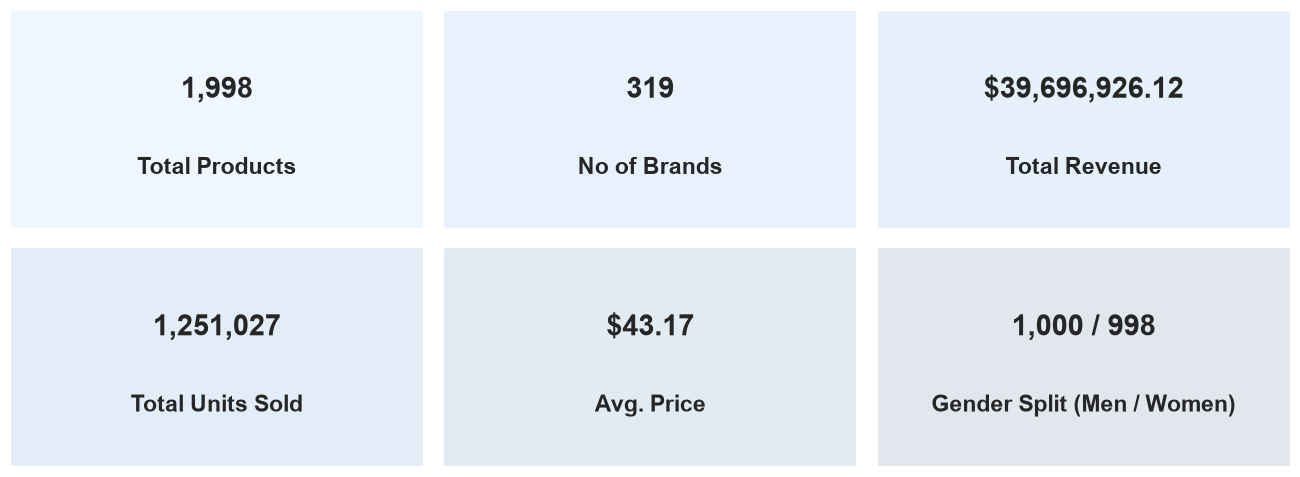

In [206]:
kpis = {
    'Total Products': f"{len(df):,}",
    'No of Brands': f"{df['Brand'].nunique():,}",
    'Total Revenue': f"${df['Revenue'].sum():,.2f}",
    'Total Units Sold': f"{df['Sold'].sum():,.0f}",
    'Avg. Price': f"${df['Price'].mean():,.2f}",
    'Gender Split (Men / Women)': f"{(df['Gender'] == 'Men').sum():,} / {(df['Gender'] == 'Women').sum():,}"
}

colors = [BLUE_3, BLUE_4, BLUE_5, BLUE_6, BLUE_7, BLUE_8]

fig, axes = plt.subplots(2, 3, figsize=(12, 4.5))

for ax, (label, value), color in zip(axes.flat, kpis.items(), colors):
    ax.axis('off')
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, facecolor=color, alpha=0.12))
    ax.text(0.5, 0.6, value, ha='center', fontsize=19, fontweight='bold')
    ax.text(0.5, 0.25, label, ha='center', fontsize=15, fontweight='bold')

plt.tight_layout()
plt.show()

### What does the product catalogue look like?

#### Which price category has the most products?


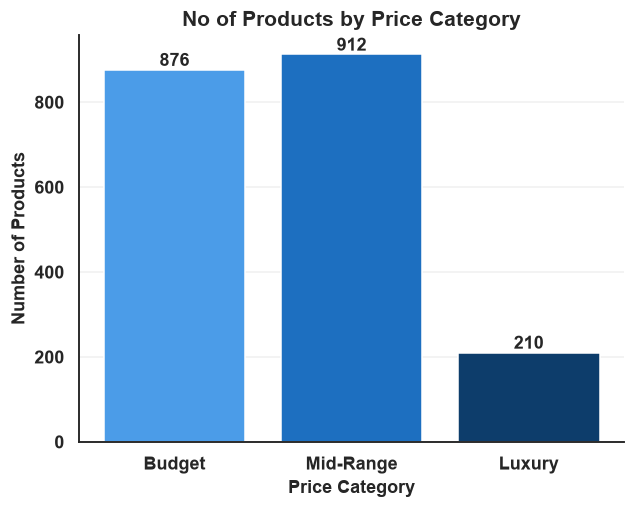

In [207]:
price_counts = df['Price_Category'].value_counts().reindex(PRICE_ORDER)

bars = plt.bar(price_counts.index, price_counts.values,
               color=[PRICE_COLORS[x] for x in price_counts.index])

plt.bar_label(bars, fontsize=12, fontweight='bold')
plt.grid(axis='y', alpha=0.3)

plt.xticks(fontweight='bold', fontsize =12,rotation = 0)
plt.yticks(fontweight='bold', fontsize =12,rotation = 0)
plt.title('No of Products by Price Category', fontsize=14, fontweight='bold')
plt.xlabel('Price Category', fontsize=12, fontweight='bold')
plt.ylabel('Number of Products', fontsize = 12, fontweight = 'bold')

plt.show()

### Insight

Most products are **Budget or Mid-Range**. Together, these categories make up about 90% of the catalogue, while Luxury products account for about 10%.

This shows that the catalogue is primarily positioned around lower- and mid-priced products.


#### Does price category affect product sales performance?


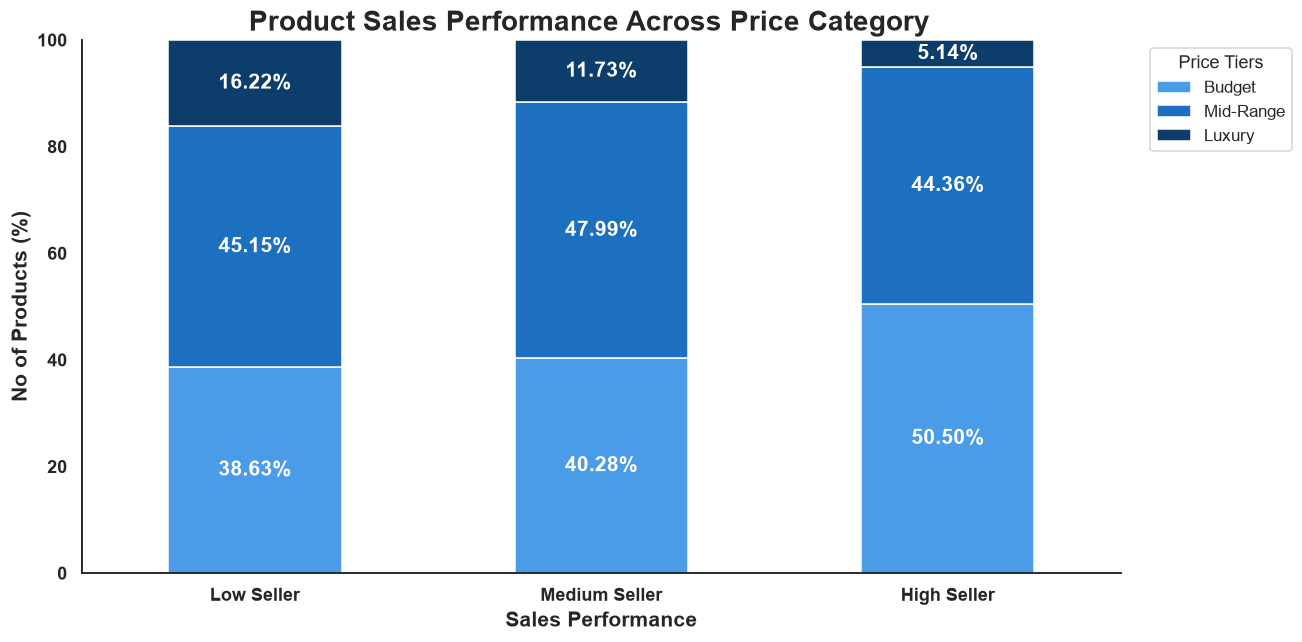

In [208]:
price_by_performance = df.groupby(
    ['Sales_Performance', 'Price_Category']
).size().unstack(fill_value=0)

price_by_performance = price_by_performance.div(
    price_by_performance.sum(axis=1),
    axis=0
).reindex(PERF_ORDER)[PRICE_ORDER] * 100

ax = price_by_performance.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    color=[PRICE_COLORS[tier] for tier in PRICE_ORDER]
)

ax.legend(
    title='Price Tiers',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        label_type='center',
        color='white',
        fontweight='bold',
        fontsize=14
    )

ax.set_title('Product Sales Performance Across Price Category   ', fontsize=18, fontweight='bold')

plt.xticks(fontweight='bold', fontsize =12,rotation = 0)
plt.yticks(fontweight='bold', fontsize =12,rotation = 0)
ax.set_xlabel('Sales Performance', fontsize=14, fontweight='bold')
ax.set_ylabel('No of Products (%)', fontsize = 14, fontweight = 'bold')
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

High-performing products are concentrated mainly in the Budget and Mid-Range categories, while Luxury products represent a smaller share of High Sellers.


### Which price segments generate the most revenue?

#### Total revenue by market segment

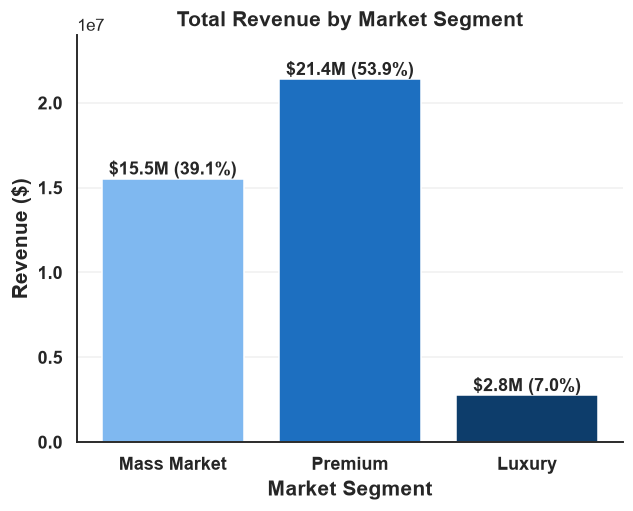

In [209]:
segment_revenue = df.groupby('Market_Segment')['Revenue'].sum().reindex(SEGMENT_ORDER)
segment_share = (segment_revenue / segment_revenue.sum() * 100).round(1)

bars = plt.bar(segment_revenue.index, segment_revenue.values,
               color=[SEGMENT_COLORS[x] for x in segment_revenue.index])

plt.bar_label(bars, labels=[f'${v/1e6:,.1f}M ({s}%)' for v, s in zip(segment_revenue.values, segment_share.values)], fontsize=12, fontweight='bold')

plt.grid(axis='y', alpha=0.3)

plt.title('Total Revenue by Market Segment', fontsize=14, fontweight='bold')
plt.xlabel('Market Segment', fontsize=14, fontweight='bold')
plt.ylabel('Revenue ($)', fontsize=14, fontweight='bold')
plt.xticks(fontweight='bold', fontsize =12,rotation = 0)
plt.yticks(fontweight='bold', fontsize =12,rotation = 0)

plt.margins(y=0.12)

plt.show()

**Result:** **Premium** generates the most total revenue (**$21.4M, 53.9%**), followed by Mass Market ($15.5M, 39.1%) and Luxury ($2.8M, 7.0%).

#### Average revenue per product

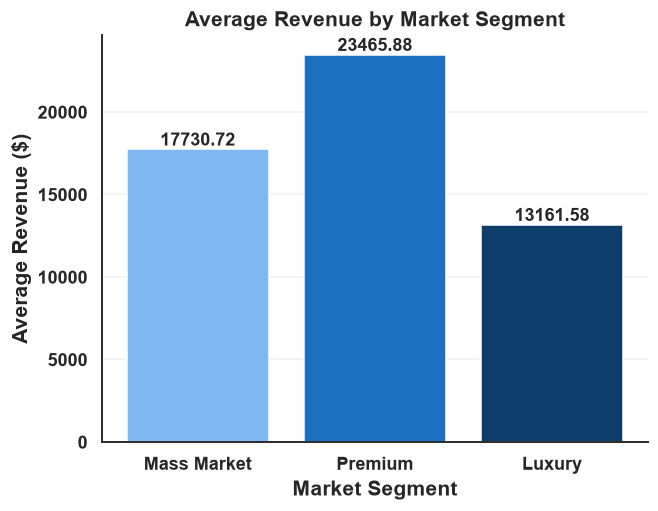

In [210]:
avg_revenue_by_segment = df.groupby('Market_Segment')['Revenue'].mean()
avg_revenue_by_segment = avg_revenue_by_segment.reindex(SEGMENT_ORDER)

bars = plt.bar(avg_revenue_by_segment.index, avg_revenue_by_segment.values,
               color=[SEGMENT_COLORS[x] for x in avg_revenue_by_segment.index])

plt.bar_label(bars, fmt='%.2f', fontsize=12, fontweight='bold')
plt.xticks(fontweight='bold', fontsize =12,rotation = 0)
plt.yticks(fontweight='bold', fontsize =12,rotation = 0)
plt.grid(axis='y', alpha=0.3)
plt.title('Average Revenue by Market Segment', fontsize=14, fontweight='bold')
plt.xlabel('Market Segment', fontsize=14, fontweight='bold')
plt.ylabel('Average Revenue ($)', fontsize=14, fontweight='bold')

plt.show()

### Insight

A higher product price does not automatically result in higher revenue. **Premium** products generate the highest average revenue in this dataset, while **Luxury** products have the highest prices but the lowest average revenue.

This indicates that price alone does not explain product performance.


### Which brands sell the most units?


In [211]:
top_brands = (df.groupby('Brand')['Sold'].sum().sort_values(ascending=False).head(10))

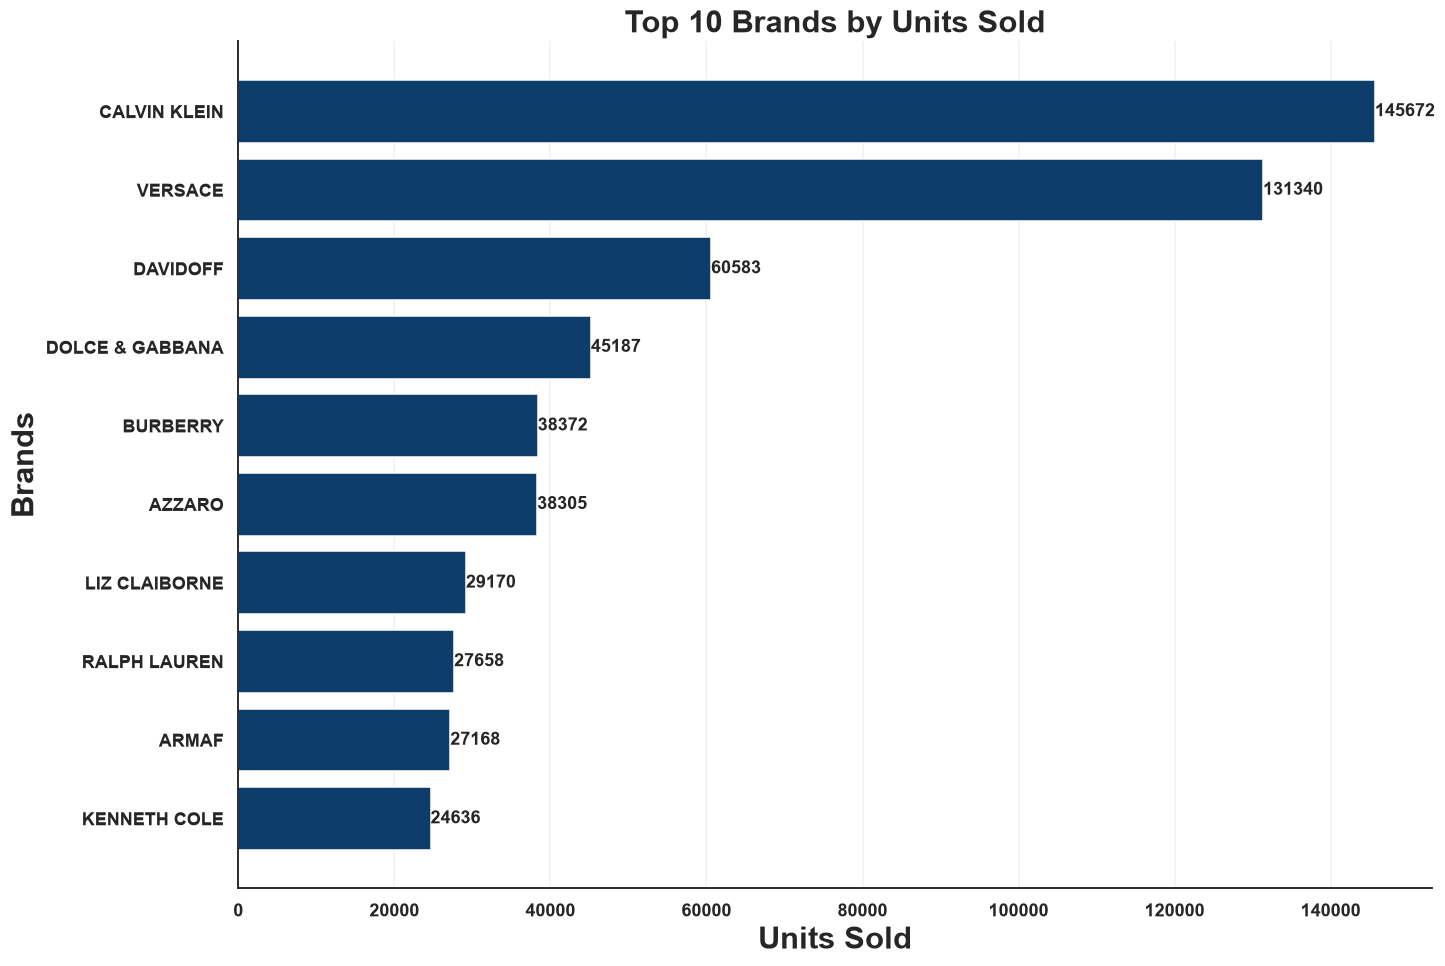

In [212]:
plt.figure(figsize=(14, 10))

bars = plt.barh(top_brands.index[::-1],top_brands.values[::-1],color=BLUE_8, height=0.8)

plt.bar_label(bars, fontsize=12, fontweight='bold')
plt.xticks(fontweight='bold', fontsize =12,rotation = 0)
plt.yticks(fontweight='bold', fontsize =12,rotation = 0)

plt.title('Top 10 Brands by Units Sold', fontsize=20, fontweight='bold')
plt.xlabel('Units Sold', fontweight='bold',fontsize=20)
plt.ylabel('Brands', fontweight='bold',fontsize=20)

plt.grid(axis='x', alpha=0.3)

plt.show()

### How concentrated are revenue and units among the top brands?

In [213]:
brand_totals = (df[df['Brand'] != 'UNKNOWN']
                .groupby('Brand')[['Revenue', 'Sold']].sum())

total_revenue = df['Revenue'].sum()
total_units = df['Sold'].sum()
n_brands = len(brand_totals)

for n in (10, 30):
    rev_share = brand_totals['Revenue'].nlargest(n).sum() / total_revenue * 100
    unit_share = brand_totals['Sold'].nlargest(n).sum() / total_units * 100
    print(f'Top {n} brands ({n / n_brands:.0%} of {n_brands} named brands): '
          f'{rev_share:.1f}% of revenue, {unit_share:.1f}% of units sold')

Top 10 brands (3% of 318 named brands): 48.1% of revenue, 45.4% of units sold
Top 30 brands (9% of 318 named brands): 73.8% of revenue, 70.4% of units sold


### Insight

The top 10 brands generate 48.1% of total revenue, and the top 30 brands generate 73.8%, so a small group of brands contributes most of the revenue.

### Does brand popularity affect Revenue Performance?


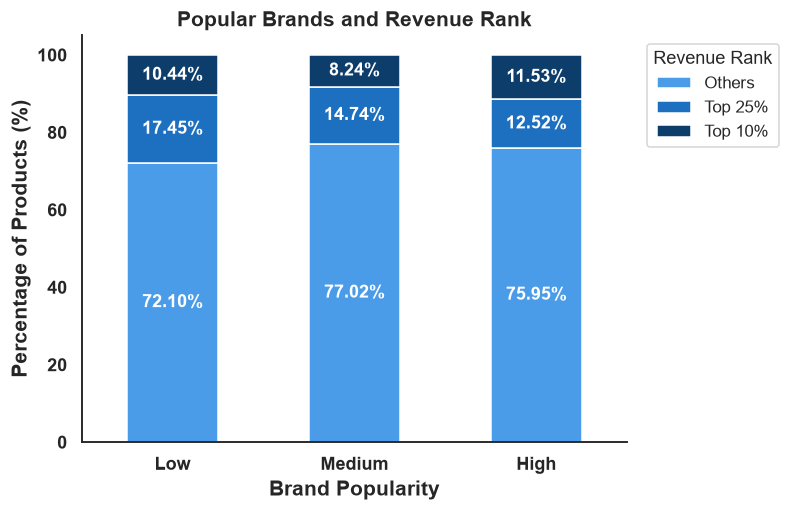

In [214]:
revenue_rank = df.groupby(
    'Brand_Popularity'
)['Revenue_Rank'].value_counts(normalize=True).unstack(fill_value=0)

revenue_rank_by_brand_popularity = revenue_rank.reindex(
    ['Low', 'Medium', 'High']
)[['Others', 'Top 25%', 'Top 10%']] * 100

ax = revenue_rank_by_brand_popularity.plot(
    kind='bar',
    stacked=True,
    color=[BLUE_4,BLUE_6, BLUE_8],
)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        label_type='center',
        color='white',
        fontweight='bold'
    )

ax.legend(
    title='Revenue Rank',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

ax.set_title('Popular Brands and Revenue Rank', fontweight='bold')
ax.set_xlabel('Brand Popularity', fontweight='bold', fontsize=14)
ax.set_ylabel('Percentage of Products (%)', fontweight='bold', fontsize=14)

plt.xticks(fontweight='bold', fontsize =12,rotation = 0)
plt.yticks(fontweight='bold', fontsize =12,rotation = 0)

plt.show()

Most products across the Low, Medium and High popularity groups fall into the `Others` revenue category.

For High-popularity brands:

- 75.95% are in `Others`
- 12.52% are in the Top 25%
- 11.53% are in the Top 10%

**Insight:** Brand popularity alone does not guarantee strong revenue performance. Even highly popular brands contain many products outside the highest revenue groups.


## Step 3: Market Drivers

The next section examines the factors behind market performance, including inventory risk, geographic revenue concentration and the difference between men's and women's product performance.


###  Which brands have the highest inventory risk?

#### Which brands have fast-selling products that may run out of stock?

In [215]:
stock_turnover_risk = df[(df['Inventory_Status'] == 'Low Stock') &(df['Stock_Turnover'] == 'Fast')]

In [216]:
stock_turnover_risk = stock_turnover_risk.groupby('Brand')['Revenue'].sum()
stock_turnover_risk = stock_turnover_risk.sort_values(ascending=False).head(10)


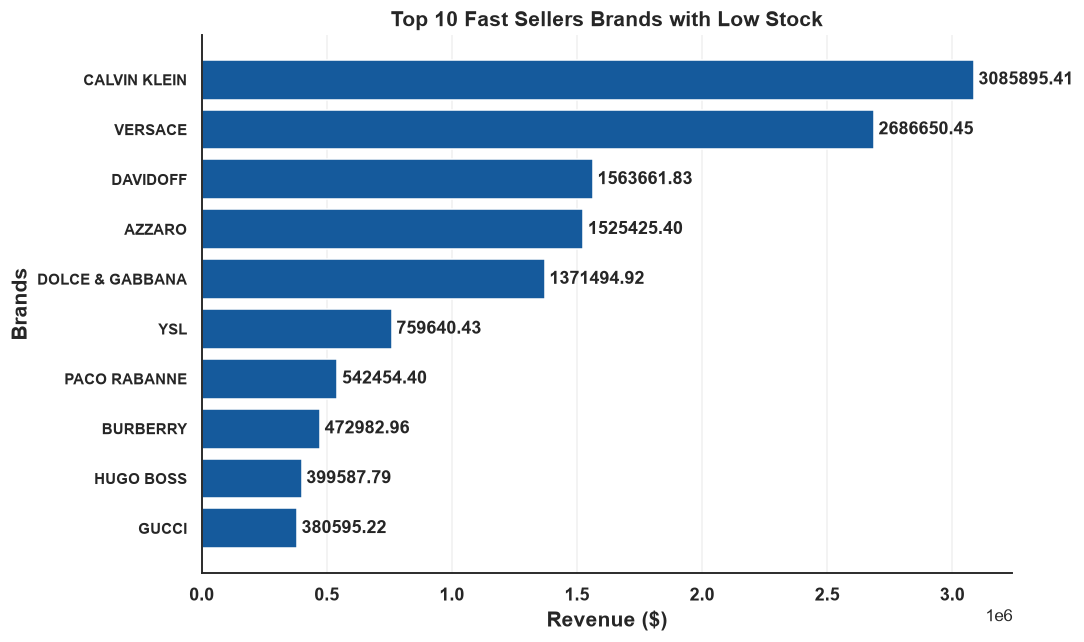

In [217]:
plt.figure(figsize=(10, 6))

bars = plt.barh(
    stock_turnover_risk.index[::-1],
    stock_turnover_risk.values[::-1],
    color=BLUE_7
)

plt.bar_label(bars, padding=3, fmt='%.2f', fontsize=12, fontweight='bold')

plt.title('Top 10 Fast Sellers Brands with Low Stock', fontsize=14, fontweight='bold')
plt.xlabel('Revenue ($)', fontweight='bold', fontsize=14)
plt.ylabel('Brands', fontweight='bold', fontsize=14)

plt.xticks(fontweight='bold', fontsize =12,rotation = 0)
plt.yticks(fontweight='bold', fontsize =10,rotation = 0)


plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

### Insight

Calvin Klein and Versace have the highest revenue generated by products that are both **fast-selling and low in stock**.

**Business implication:** These brands require close inventory monitoring because stockouts could affect products that have already demonstrated strong sales.


### How concentrated is revenue across countries?


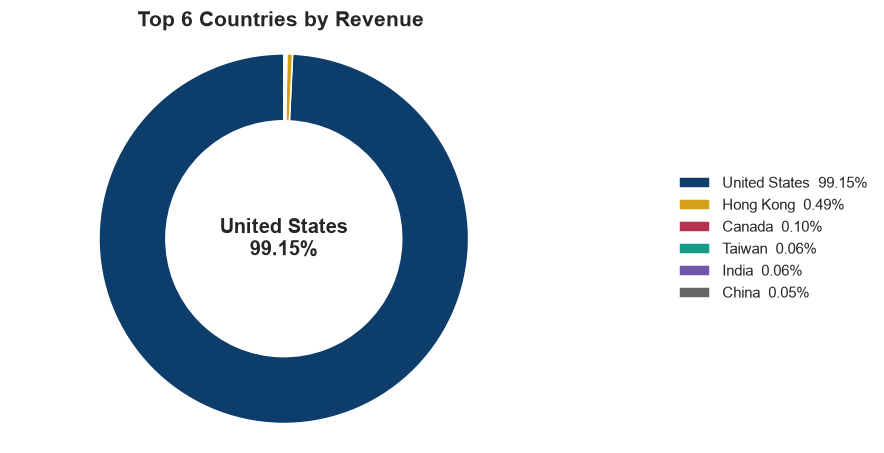

In [218]:
country = df.groupby('Country')['Revenue'].sum().nlargest(6)
share = country / df['Revenue'].sum() * 100
colors = [BLUE_8, '#D4A017', '#B8324B', '#159A8A', '#7056A8', '#666666']

wedges, _ = plt.pie(share, startangle=90, radius=1.05, colors=colors,
                    wedgeprops=dict(width=0.38, edgecolor='white'))

plt.legend(wedges, [f'{c}  {v:.2f}%' for c, v in share.items()],
           loc='center left', bbox_to_anchor=(1.20, 0.5),
           frameon=False, fontsize=10)

plt.text(0, 0, 'United States\n99.15%', ha='center', va='center',
         fontsize=13, fontweight='bold')

plt.title('Top 6 Countries by Revenue ',  fontweight='bold')
plt.axis('equal')
plt.show()


**Result:** The United States accounts for almost all of the revenue in the dataset.

**Important note:** The dataset is heavily concentrated in the United States, so country-level comparisons should be treated carefully until the geographic distribution is validated.


###  How do men's and women's products compare?


In [219]:
gender_counts = df['Gender'].value_counts()
gender_share = (gender_counts / gender_counts.sum() * 100).round(1)

print(gender_counts)
print()
print(gender_share)

Gender
Men      1000
Women     998
Name: count, dtype: int64

Gender
Men      50.1
Women    49.9
Name: count, dtype: float64


In [220]:
gender_summary = df.groupby('Gender').agg(
    Products=('Product', 'count'),
    Units_Sold=('Sold', 'sum'),
    Revenue=('Revenue', 'sum'),
    Avg_Price=('Price', 'mean'),
    Avg_Revenue_per_Product=('Revenue', 'mean'),
    Median_Revenue_per_Product=('Revenue', 'median')
).round(2)

gender_summary['Revenue_Share_%'] = (gender_summary['Revenue'] / gender_summary['Revenue'].sum() * 100).round(1)
gender_summary

,Products,Units_Sold,Revenue,Avg_Price,Avg_Revenue_per_Product,Median_Revenue_per_Product,Revenue_Share_%
Gender,,,,,,,
Men,1000,761669.0,25809208.09,46.48,25809.21,1865.42,65.0
Women,998,489358.0,13887718.03,39.86,13915.55,1752.05,35.0


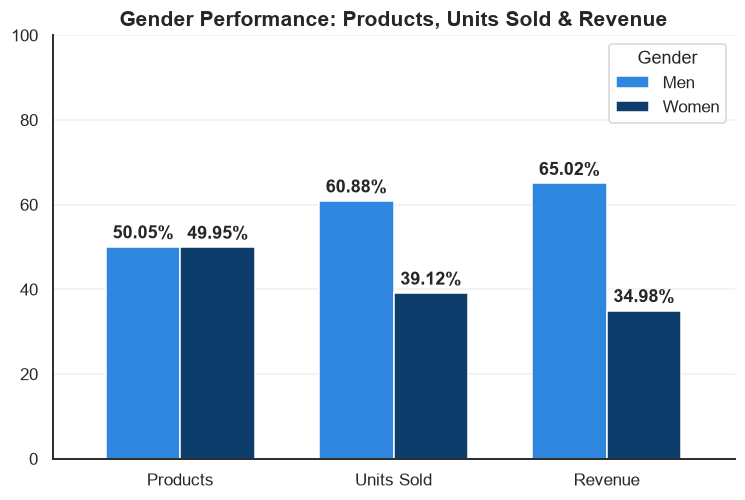

In [221]:
gender_shares = pd.DataFrame({
    'Products': gender_summary['Products'] / gender_summary['Products'].sum() * 100,
    'Units Sold': gender_summary['Units_Sold'] / gender_summary['Units_Sold'].sum() * 100,
    'Revenue': gender_summary['Revenue'] / gender_summary['Revenue'].sum() * 100
})

ax = gender_shares.T.plot(kind='bar', rot=0, figsize=(8, 5), width=0.7,
                          color=[GENDER_COLORS.get(g, GREY) for g in gender_shares.T.columns])
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f%%', padding=3, fontweight='bold')

ax.set_title('Gender Performance: Products, Units Sold & Revenue')
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_ylim(0, 100)
ax.grid(axis='y', alpha=0.3)
plt.show()


### Insight

The catalogue is almost evenly split, with **1,000 men's products and 998 women's products**. However, men's fragrances generate **65.0% of revenue and 60.9% of units sold**.

Men's products also have a higher average price (**$46.48 vs $39.86**). The median revenue per product is much closer (**$1,865 vs $1,752**), suggesting that the overall gap is driven mainly by a smaller group of high-earning men's products rather than by the typical product.

This leads to the next question: **what is driving the difference?**


### What drives the gender revenue gap?

Three possible drivers are examined:

- Number of products
- Market segment and price category
- Brands


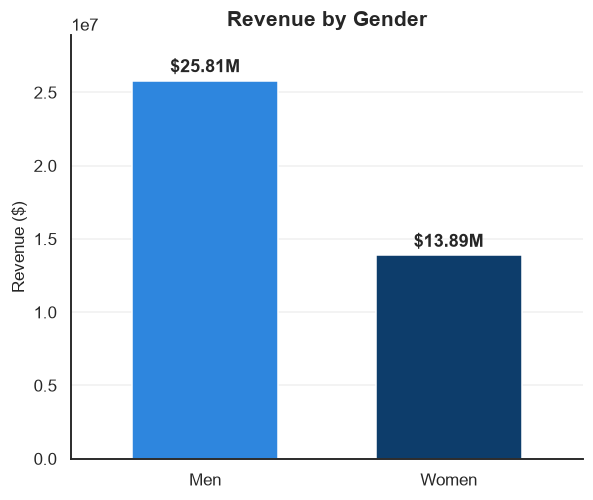

,Products,Revenue,Avg_Revenue_per_Product
Gender,,,
Men,1000,25809208.09,25809.21
Women,998,13887718.03,13915.55


In [222]:
gender_rev = df.groupby('Gender').agg(
    Products=('Product', 'count'),
    Revenue=('Revenue', 'sum'),
    Avg_Revenue_per_Product=('Revenue', 'mean')
).round(2)

ax = gender_rev['Revenue'].plot(kind='bar', rot=0, figsize=(6, 5), width=0.6,
                                color=[GENDER_COLORS.get(g, GREY) for g in gender_rev.index])
ax.bar_label(ax.containers[0], labels=[f'${v/1e6:,.2f}M' for v in gender_rev['Revenue']],
             fontweight='bold', padding=3)

ax.set_title('Revenue by Gender')
ax.set_xlabel('')
ax.set_ylabel('Revenue ($)')
ax.margins(y=0.12)
ax.grid(axis='y', alpha=0.3)
plt.show()

gender_rev

#### Cause 1: Is it the number of products?


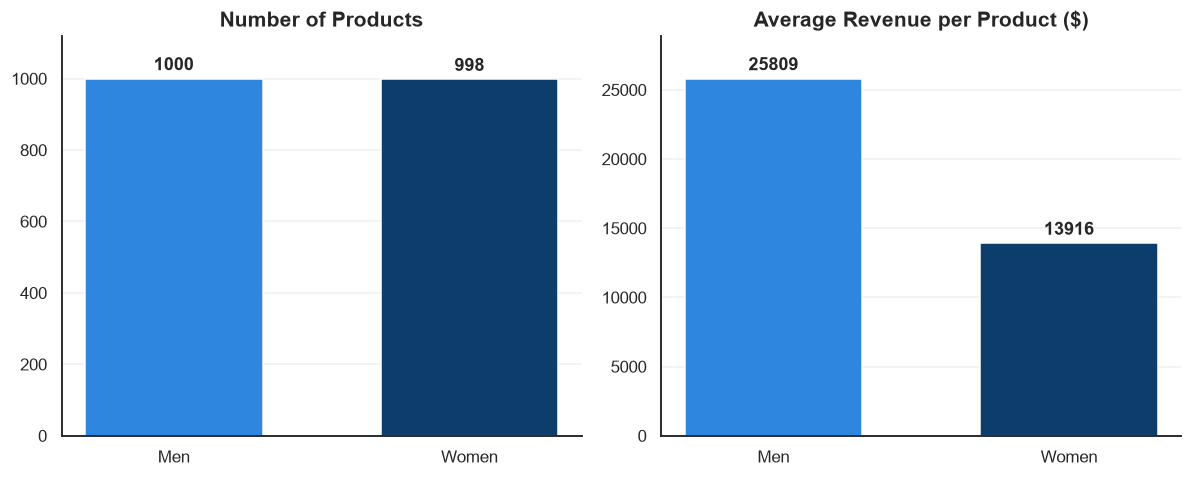

In [223]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, col, title in [(axes[0], 'Products', 'Number of Products'),
                       (axes[1], 'Avg_Revenue_per_Product', 'Average Revenue per Product ($)')]:
    bars = ax.bar(gender_rev.index, gender_rev[col], width=0.6,
                  color=[GENDER_COLORS.get(g, GREY) for g in gender_rev.index])
    ax.bar_label(bars, fmt='%.0f', padding=3, fontweight='bold')
    ax.set_title(title)
    ax.margins(y=0.12)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Result:** No. Men have 1,000 products and women have 998, so catalogue size does not explain the gap.

The difference is in revenue per product: men's products earn about **$25,809** on average, compared with **$13,916** for women's products.


#### Cause 2: Is it the market segment or price category?

Revenue is compared by gender within each group, alongside the number of products in each group. This separates differences caused by catalogue size from differences in product performance.


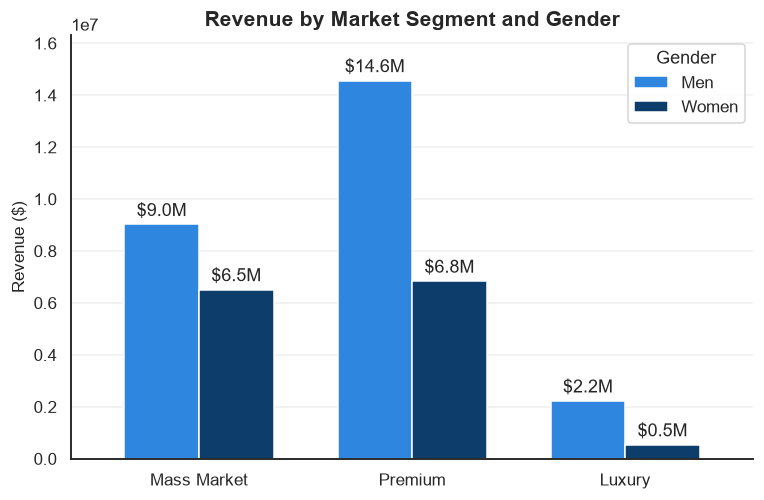

In [224]:
def gender_revenue_by(col, order):
    t = df.groupby([col, 'Gender'])['Revenue'].sum().unstack().reindex(order)
    ax = t.plot(kind='bar', rot=0, figsize=(8, 5), width=0.7,
                color=[GENDER_COLORS.get(g, GREY) for g in t.columns])
    for c in ax.containers:
        ax.bar_label(c, labels=[f'${v/1e6:,.1f}M' for v in c.datavalues], padding=3)
    ax.set_title(f'Revenue by {col.replace("_", " ")} and Gender')
    ax.set_xlabel('')
    ax.set_ylabel('Revenue ($)')
    ax.margins(y=0.12)
    ax.grid(axis='y', alpha=0.3)
    plt.show()

gender_revenue_by('Market_Segment', SEGMENT_ORDER)


In [225]:
# Product counts, to compare against the revenue bars above
print('Products by Market Segment')
display(df.groupby(['Market_Segment', 'Gender']).size().unstack().reindex(SEGMENT_ORDER))

print('Average revenue per product by Market Segment')
display(df.groupby(['Market_Segment', 'Gender'])['Revenue'].mean().unstack().reindex(SEGMENT_ORDER).round(2))

Products by Market Segment


Gender,Men,Women
Market_Segment,,
Mass Market,416,460
Premium,449,463
Luxury,135,75


Average revenue per product by Market Segment


Gender,Men,Women
Market_Segment,,
Mass Market,21683.62,14155.92
Premium,32432.81,14770.10
Luxury,16492.53,7165.87


**Result:** This explains part of the difference, but it is not the main cause.

Men lead in every segment. The biggest gap is in Premium, where 449 men's products and 463 women's products generate $14.6M and $6.8M respectively. Because the product counts are close, the difference is mainly about how well the products perform, not how many products there are.

Luxury has more men's products (135 vs 75), which also contributes to the gap.



#### Cause 3: Is it the brands?

Revenue is compared by brand for men and women, and the revenue gap is measured for each brand. The brands with the largest gaps identify the main contributors to the overall difference.


In [226]:
brand_gap = df.groupby(['Brand', 'Gender'])['Revenue'].sum().unstack(fill_value=0)

gender_order = df.groupby('Gender')['Revenue'].sum().sort_values(ascending=False).index
top_gender, other_gender = gender_order[0], gender_order[1]

brand_gap['Gap'] = brand_gap[top_gender] - brand_gap[other_gender]
print(f'Gap = {top_gender} revenue minus {other_gender} revenue, per brand')
print(brand_gap.sort_values('Gap', ascending=False).head(5).round(0))

total_gap = brand_gap['Gap'].sum()
top5_gap = brand_gap['Gap'].nlargest(5).sum()
print(f'\nThe top 5 brands account for {top5_gap / total_gap:.0%} of the total gap')
print('(Above 100% means some brands lean the other way and cancel part of the gap out.)')

Gap = Men revenue minus Women revenue, per brand
Gender              Men      Women        Gap
Brand                                        
VERSACE       3718811.0   920412.0  2798399.0
AZZARO        1673079.0        0.0  1673079.0
DAVIDOFF      1576826.0   111665.0  1465161.0
CALVIN KLEIN  2492205.0  1274842.0  1217363.0
PACO RABANNE   972897.0    98972.0   873926.0

The top 5 brands account for 67% of the total gap
(Above 100% means some brands lean the other way and cancel part of the gap out.)


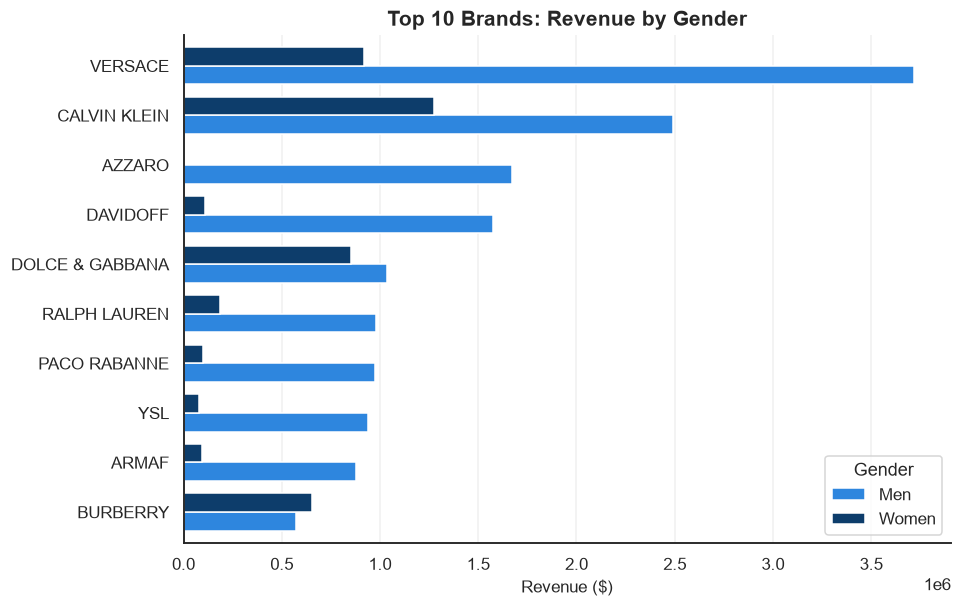

In [227]:
top10_brands = brand_gap.drop(columns='Gap')
top10_brands = top10_brands.loc[top10_brands.sum(axis=1).nlargest(10).index].sort_values(top_gender)

ax = top10_brands.plot(kind='barh', figsize=(9, 6), width=0.75,
                       color=[GENDER_COLORS.get(g, GREY) for g in top10_brands.columns])
ax.set_title('Top 10 Brands: Revenue by Gender')
ax.set_xlabel('Revenue ($)')
ax.set_ylabel('')
ax.grid(axis='x', alpha=0.3)
plt.show()

**Result:** Yes. A small group of men's brands is the main driver.

The largest gaps are seen in:

- Versace: $3.72M vs $0.92M
- Azzaro: $1.67M vs none
- Davidoff: $1.58M vs $0.11M
- Calvin Klein: $2.49M vs $1.27M
- Paco Rabanne: $0.97M vs $0.10M

These five brands account for **67% of the total gender revenue gap**.


### Insight

The men's and women's revenue gap is mainly a **brand-level difference**.

Both genders have almost the same number of products, and men lead in every segment. However, much of the difference is concentrated in a few strong men's brands: **Versace, Azzaro, Davidoff, Calvin Klein and Paco Rabanne**.

The median product earns about the same for both genders, indicating that the overall gap is driven by a smaller group of high-earning men's products rather than the catalogue as a whole.


## Step 4: Price & Sales

This section examines the relationship between price and sales. Luxury products have the highest prices but the lowest average revenue, so the analysis tests whether higher prices are linked to lower sales and which price ranges perform best.


### Does a higher price mean lower sales?

The relationship between price and sales is examined through price categories, sales performance, correlation and gender-level comparisons.


#### Check 1: How many units does each price category sell?


In [228]:
price_units = df.groupby('Price_Category').agg(
    Products=('Product', 'count'),
    Total_Units_Sold=('Sold', 'sum'),
    Avg_Units_Sold=('Sold', 'mean'),
).reindex(PRICE_ORDER).round(1)

price_units['Product_Share_%'] = (price_units['Products'] / price_units['Products'].sum() * 100).round(1)
price_units['Unit_Share_%'] = (price_units['Total_Units_Sold'] / price_units['Total_Units_Sold'].sum() * 100).round(1)
price_units

,Products,Total_Units_Sold,Avg_Units_Sold,Product_Share_%,Unit_Share_%
Price_Category,,,,,
Budget,876,735395.0,839.5,43.8,58.8
Mid-Range,912,489486.0,536.7,45.6,39.1
Luxury,210,26146.0,124.5,10.5,2.1


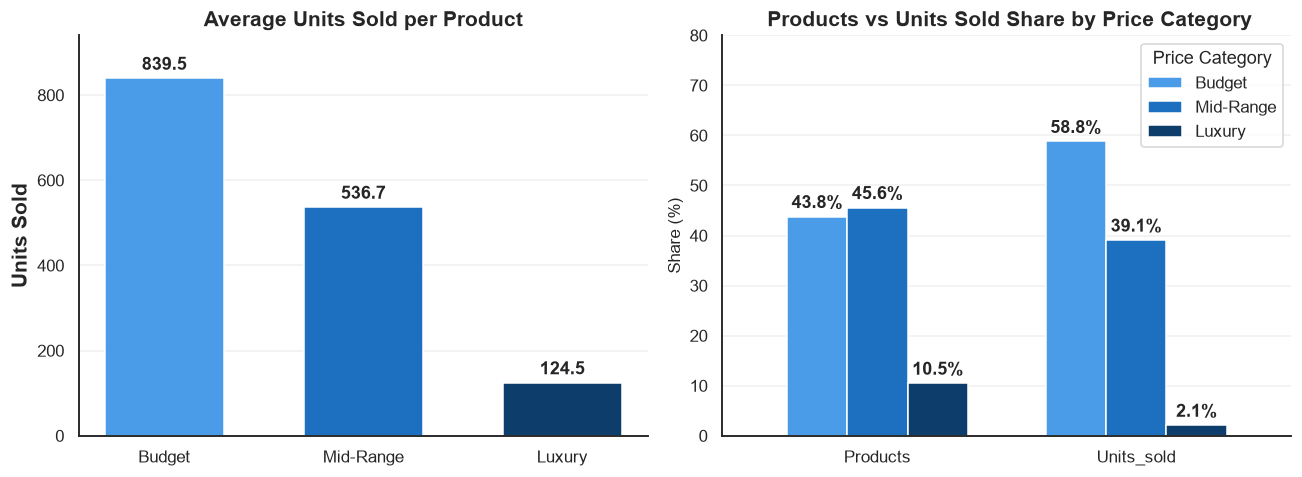

In [229]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bars = axes[0].bar(price_units.index, price_units['Avg_Units_Sold'],
                   color=[PRICE_COLORS[x] for x in price_units.index], width=0.6)
axes[0].bar_label(bars, fmt='%.1f', padding=3, fontweight='bold')
axes[0].set_title('Average Units Sold per Product')
axes[0].set_ylabel('Units Sold', fontsize=14, fontweight='bold')
axes[0].margins(y=0.12)

share_compare = price_units[['Product_Share_%', 'Unit_Share_%']]
share_compare.columns = ['Products', 'Units_sold']
share_compare.T.plot(kind='bar', rot=0, ax=axes[1], width=0.7,
                     color=[PRICE_COLORS[x] for x in share_compare.T.columns])
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.1f%%', padding=3, fontweight='bold')
axes[1].set_title(' Products vs Units Sold Share by Price Category')
axes[1].set_ylabel('Share (%)')
axes[1].set_ylim(0, 80)
axes[1].legend(title='Price Category')

for ax in axes:
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Result:** Units sold generally fall as price rises.

The average Budget product sells **839.5 units**, a Mid-Range product sells **536.7**, and a Luxury product sells **124.5**.

Luxury makes up 10.5% of products but only 2.1% of units sold, while Budget makes up 43.8% of products and 58.8% of units sold.


#### Check 2: What does the sales performance look like inside each price category?

Each price category is examined separately to compare the share of High, Medium and Low Sellers.


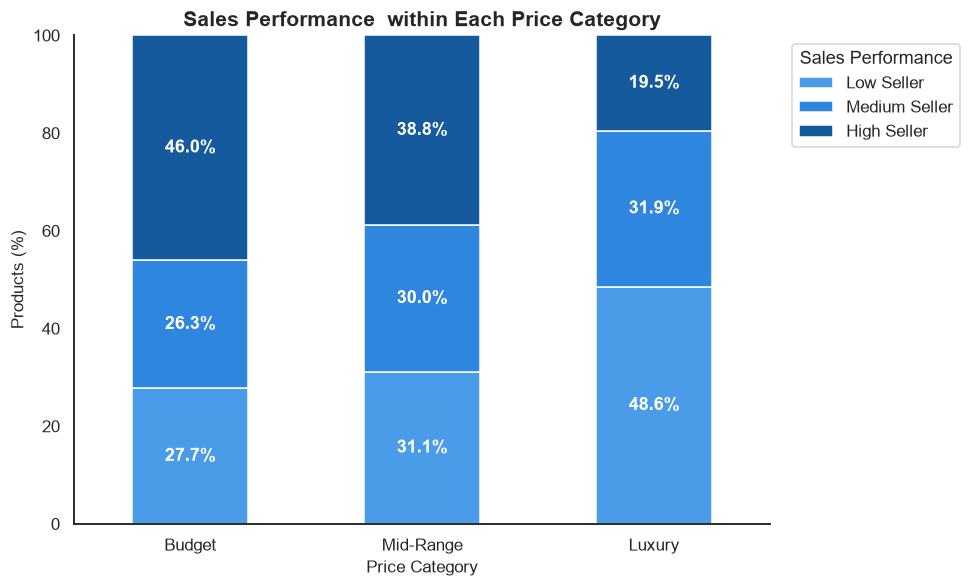

In [230]:
perf_by_price = df.groupby(['Price_Category', 'Sales_Performance']).size().unstack(fill_value=0)
perf_by_price = perf_by_price.div(perf_by_price.sum(axis=1), axis=0).reindex(PRICE_ORDER)[PERF_ORDER] * 100

ax = perf_by_price.plot(kind='bar', stacked=True, rot=0, figsize=(9, 5.5),
                        color=[PERF_COLORS[p] for p in PERF_ORDER])
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')

ax.legend(title='Sales Performance', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.set_title('Sales Performance  within Each Price Category')
ax.set_xlabel('Price Category')
ax.set_ylabel('Products (%)')
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

**Result:** The same pattern appears in sales performance. **46.0% of Budget products are High Sellers**, compared with 38.8% of Mid-Range and 19.5% of Luxury.

Almost half of Luxury products (48.6%) are Low Sellers.


#### Check 3: How strong is the link between price and units sold?

Correlation measures how closely two variables move together and ranges from -1 to +1. Spearman correlation is used because the price and sales data are heavily skewed.


In [231]:
df[['Price', 'Sold', 'Revenue']].corr(method='spearman').round(2)

,Price,Sold,Revenue
Price,1.00,-0.18,0.13
Sold,-0.18,1.00,0.94
Revenue,0.13,0.94,1.00


**Result:** The relationship between price and units sold is **weak and negative (-0.18)**. Higher prices are linked to slightly fewer units sold, but price explains little on its own.

Price and revenue are also only weakly related (0.13), while units sold and revenue are strongly related (0.94). This means that, in this dataset, revenue is much more closely connected to how many units a product sells than to price alone.


#### Check 4: Does the pattern hold for both genders?

The price and sales relationship is compared separately for men and women to determine whether the overall pattern is consistent across both groups.


In [232]:
gender_price_units = df.groupby(['Price_Category', 'Gender'])['Sold'].agg(['median', 'mean']).unstack().reindex(PRICE_ORDER).round(0)
gender_price_units

median          mean       
Gender            Men Women     Men  Women
Price_Category                            
Budget           75.0  81.0  1000.0  694.0
Mid-Range        44.0  40.0   723.0  356.0
Luxury           24.0  15.0   154.0   72.0

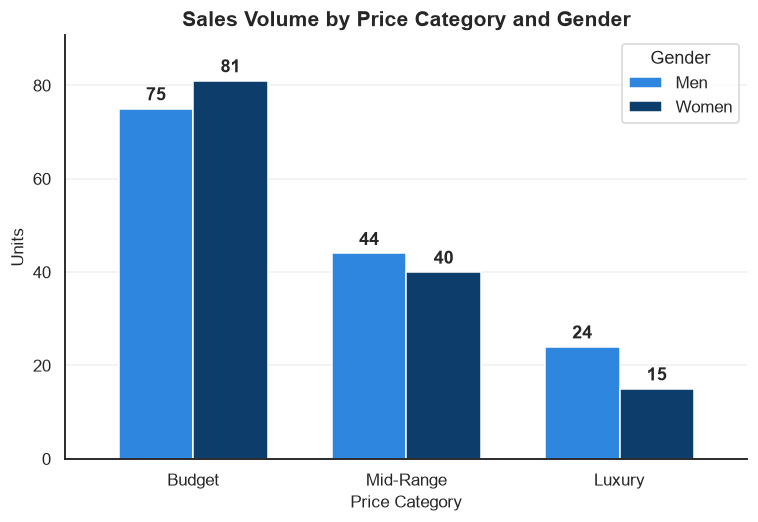

In [233]:
gender_median_units = df.groupby(['Price_Category', 'Gender'])['Sold'].median().unstack().reindex(PRICE_ORDER)

ax = gender_median_units.plot(kind='bar', rot=0, figsize=(8, 5), width=0.7,
                              color=[GENDER_COLORS.get(g, GREY) for g in gender_median_units.columns])
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f', padding=3, fontweight='bold')

ax.set_title('Sales Volume by Price Category and Gender')
ax.set_xlabel('Price Category')
ax.set_ylabel('Units')
ax.margins(y=0.12)
ax.grid(axis='y', alpha=0.3)
plt.show()

**Result:** Units fall as price rises for both genders. In the typical product, men and women sell similar units in Budget (75 vs 81) and Mid-Range (44 vs 40), while men lead in Luxury (24 vs 15).

This supports the earlier finding that the overall men's revenue advantage is being driven by a smaller group of top-selling products rather than by higher sales across every product.


### Which price range performs best?

The three broad price categories can hide useful differences. The products are therefore divided into five price bands of roughly equal size, and their sales and revenue performance are compared.


In [234]:
price_edges = pd.qcut(df['Price'], 5, retbins=True)[1]
band_labels = [f'${price_edges[i]:.0f}-${price_edges[i+1]:.0f}' for i in range(5)]
price_band = pd.qcut(df['Price'], 5, labels=band_labels)

band_summary = df.groupby(price_band, observed=True).agg(
    Products=('Product', 'count'),
    Median_Units=('Sold', 'median'),
    Total_Units=('Sold', 'sum'),
    Avg_Revenue=('Revenue', 'mean'),
    High_Seller_Share=('Sales_Performance', lambda s: (s == 'High Seller').mean() * 100)
).round(1)
band_summary

,Products,Median_Units,Total_Units,Avg_Revenue,High_Seller_Share
Price,,,,,
$2-$19,400,75.5,240451.0,8106.2,45.5
$19-$30,399,82.0,468284.0,28803.4,47.4
$30-$40,404,73.0,272856.0,23731.5,44.6
$40-$60,418,37.0,203313.0,23578.9,37.6
$60-$300,377,26.0,66123.0,14637.6,23.9


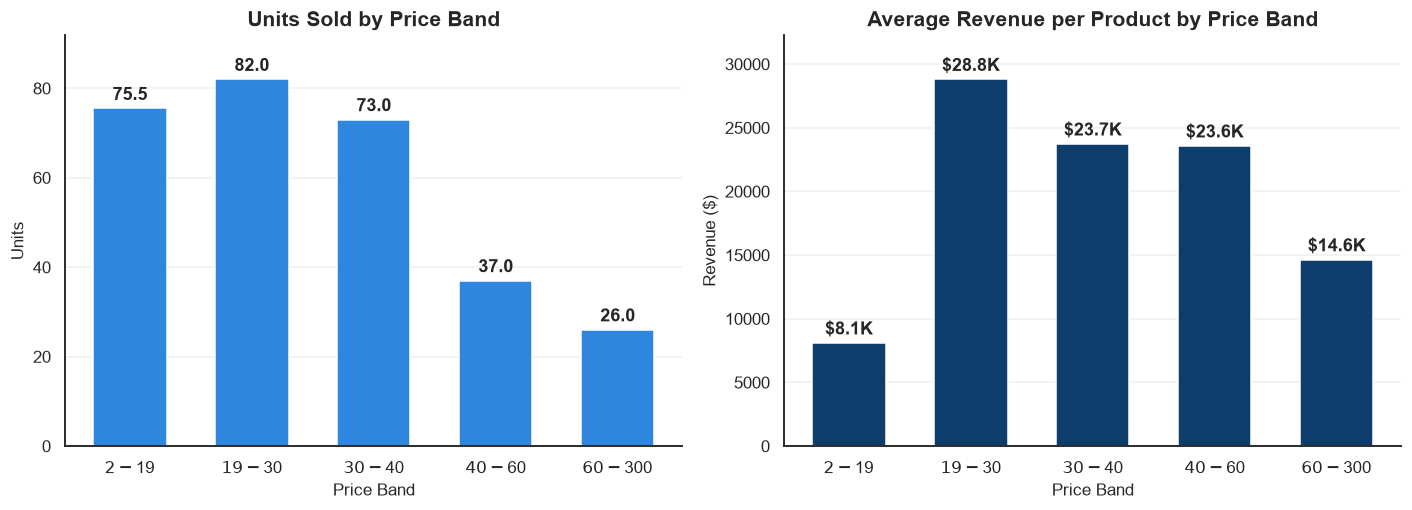

In [235]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

bars = axes[0].bar(band_summary.index, band_summary['Median_Units'], color=BLUE_5, width=0.6)
axes[0].bar_label(bars, fmt='%.1f', padding=3, fontweight='bold')
axes[0].set_title('Units Sold by Price Band')
axes[0].set_ylabel('Units')

bars = axes[1].bar(band_summary.index, band_summary['Avg_Revenue'], color=BLUE_8, width=0.6)
axes[1].bar_label(bars, labels=[f'${v/1e3:,.1f}K' for v in band_summary['Avg_Revenue']],
                  padding=3, fontweight='bold')
axes[1].set_title('Average Revenue per Product by Price Band')
axes[1].set_ylabel('Revenue ($)')

for ax in axes:
    ax.set_xlabel('Price Band')
    ax.margins(y=0.12)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Result:** Units stay fairly steady up to about $40, with a median of 73 to 82 units in the first three bands. They then fall to 37 units in the $40-$60 band and 26 above $60.

The **$19-$30 range** has the highest average revenue per product ($28.8K) and the highest share of High Sellers (47.4%), but part of this comes from a small number of best-sellers (see the check below).

The cheapest band earns much less ($8.1K) because it sells similar numbers of units at a much lower price. This shows that cheaper is not always better.


#### Is the $19-$30 peak driven by a few best-sellers?

Average revenue can be influenced by a small number of very strong sellers. The 20 best-selling products are therefore removed and the price bands are compared again.


In [236]:
top_sellers = df.nlargest(20, 'Sold').index

band_check = pd.DataFrame({
    'All_Products': df.groupby(price_band, observed=True)['Revenue'].mean(),
    'Without_Top_20_Sellers': df.drop(top_sellers).groupby(price_band.drop(top_sellers), observed=True)['Revenue'].mean(),
    'Top_20_Sellers_in_Band': price_band[top_sellers].value_counts()
}).fillna(0).round(0)
band_check

,All_Products,Without_Top_20_Sellers,Top_20_Sellers_in_Band
Price,,,
$2-$19,8106.0,7311.0,3
$19-$30,28803.0,15365.0,11
$30-$40,23731.0,16996.0,4
$40-$60,23579.0,17976.0,2
$60-$300,14638.0,14638.0,0


**Result:** Without the 20 best-selling products, the average revenue of the $19-$30 band falls from $28.8K to $15.4K, and it is no longer the highest band ($17.0K for $30-$40 and $18.0K for $40-$60). 11 of the 20 best-selling products sit in this band.

So the $19-$30 peak depends on a few best-sellers. It is a useful reference, but not strong evidence of a single best price point.

### Insight

Price has an effect on sales, but it does not explain sales performance on its own.

Products priced above $40 sell noticeably fewer units, and Luxury is the weakest category by unit sales. The $19 to $30 range has the highest average revenue, but this result depends on a small number of best-sellers, so there is no strong evidence of one single best price point.

The weak price-to-units correlation (-0.18) also indicates that other factors, including brand and product demand, are likely to influence performance.


## Step 5: Inventory & Action

The earlier sections identified what sells, what drives performance and how price relates to sales. This section translates those findings into practical inventory decisions.


#### Which products should be restocked first?

The analysis moves from brand-level performance to individual products to identify items that are **fast-selling and low in stock**.

Products with zero units available are the most urgent because they cannot generate additional sales until stock is replenished.


In [237]:
restock = df[(df['Inventory_Status'] == 'Low Stock') & (df['Stock_Turnover'] == 'Fast')].copy()

restock['Priority'] = restock['Available'].eq(0).map({
    True: 'Priority 1: Out of stock',
    False: 'Priority 2: Almost out (1-4 left)'
})

restock_summary = restock.groupby('Priority').agg(
    Products=('Product', 'count'),
    Revenue=('Revenue', 'sum')
).round(0)
restock_summary['Share_of_Total_Revenue_%'] = (restock_summary['Revenue'] / df['Revenue'].sum() * 100).round(1)

print(f"Fast-selling, low-stock products: {len(restock)} ({len(restock) / len(df):.1%} of all products)")
restock_summary

Fast-selling, low-stock products: 414 (20.7% of all products)


,Products,Revenue,Share_of_Total_Revenue_%
Priority,,,
Priority 1: Out of stock,241,17584367.0,44.3
Priority 2: Almost out (1-4 left),173,1447245.0,3.6


In [238]:
restock_top = restock.sort_values('Revenue', ascending=False).head(10)
restock_top[['Brand', 'Product', 'Gender', 'Price', 'Sold', 'Available', 'Revenue']].round(2)

,Brand,Product,Gender,Price,Sold,Available,Revenue
319,AZZARO,Chrome by Azzaro 6.7 / 6.8 oz EDT Cologne for ...,Men,46.33,30655.0,0.0,1420246.15
658,CALVIN KLEIN,Ck One by Calvin Klein Cologne Perfume Unisex ...,Men,23.89,54052.0,0.0,1291302.28
464,VERSACE,Versace Eros by Gianni Versace 3.4 oz EDT Colo...,Men,39.77,31718.0,0.0,1261424.86
1826,DAVIDOFF,Cool Water by Davidoff 4.2 oz EDT Cologne for ...,Men,25.23,40130.0,0.0,1012479.90
1263,VERSACE,Versace Pour Homme Signature by Versace 3.4 oz...,Men,36.88,19899.0,0.0,733875.12
300,CALVIN KLEIN,OBSESSION by Calvin Klein 4.0 oz 4 MEN edt Col...,Men,23.56,24048.0,0.0,566570.88
266,DAVIDOFF,Cool Water by Davidoff Cologne for Men 6.7 / 6...,Men,38.24,13549.0,0.0,518113.76
603,CALVIN KLEIN,Escape by Calvin Klein EDP Perfume for Women 3...,Women,26.66,17854.0,0.0,475987.64
1020,PACO RABANNE,1 Million by Paco Rabanne 3.4 oz EDT Cologne f...,Men,47.99,8877.0,0.0,426007.23
1198,HUGO BOSS,Hugo by Hugo Boss 6.7 oz EDT Cologne for Men B...,Men,50.79,7506.0,0.0,381229.74


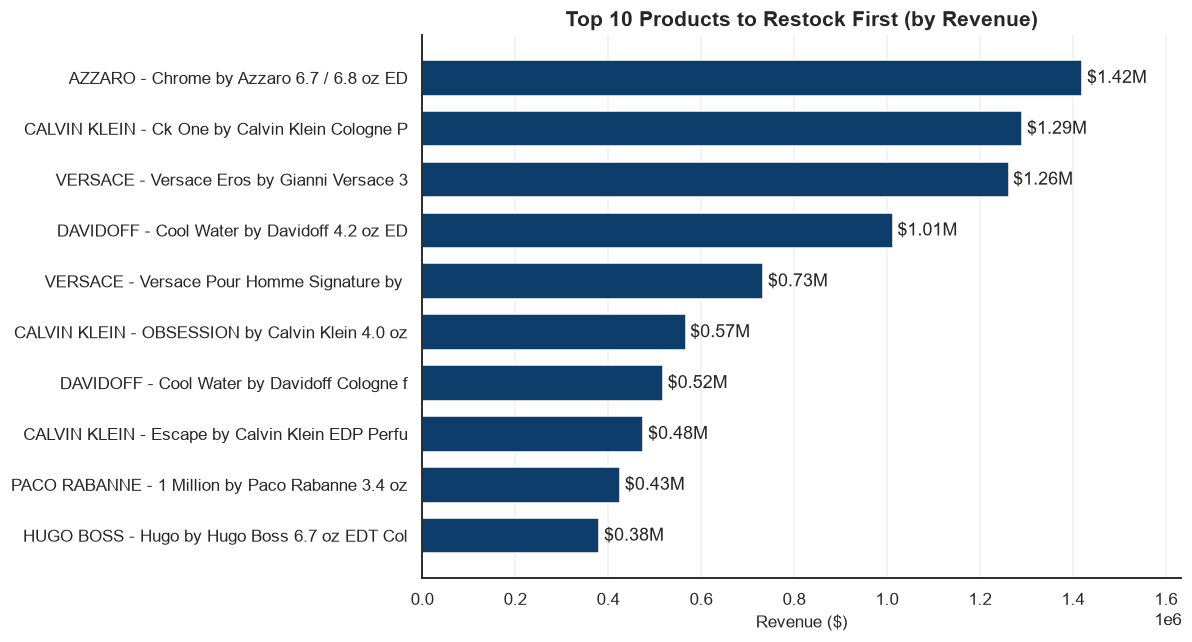

In [239]:
labels = restock_top['Brand'] + ' - ' + restock_top['Product'].str[:32]

plt.figure(figsize=(11, 6))
bars = plt.barh(labels[::-1], restock_top['Revenue'][::-1], color=BLUE_8, height=0.7)
plt.bar_label(bars, labels=[f'${v/1e6:,.2f}M' for v in restock_top['Revenue'][::-1]], padding=3)

plt.title('Top 10 Products to Restock First (by Revenue)')
plt.xlabel('Revenue ($)')
plt.xlim(0, restock_top['Revenue'].max() * 1.15)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Result:** 414 products (20.7% of the catalogue) are fast-selling but low in stock. Together, these products account for **47.9% of total revenue** in the dataset.

Of these:

- **241 products** have zero units available.
- **173 products** have only 1 to 4 units left.

The ten highest-revenue products on the list are all at zero stock, and nine are men's fragrances. Azzaro Chrome ($1.42M), CK One ($1.29M), Versace Eros ($1.26M) and Cool Water by Davidoff ($1.01M) lead the list.

These figures describe revenue already generated by the products. They do not mean that the same amount of revenue is currently at risk.


**Action:** First confirm whether zero-stock products are sold out or discontinued, because the dataset cannot distinguish between the two.

If the products are still active, prioritise the highest-revenue items for restocking, followed by the remaining Priority 1 products. Review Priority 2 products regularly to reduce the risk of future stockouts.


#### Which slow-moving stock should be reduced?

The opposite inventory issue is stock that is taking longer to sell.

Slow-moving products that are not already low in stock are reviewed, and their **retail-value stock** is estimated as `Available × Price`.

This is a retail-value estimate, not the company's actual inventory cost.


In [240]:
slow = df[(df['Stock_Turnover'] == 'Slow') & (df['Inventory_Status'] != 'Low Stock')].copy()

slow['Stock_Value'] = slow['Available'] * slow['Price']
slow['Action'] = slow['Inventory_Status'].map({
    'High Stock': 'Markdown or bundle',
    'Medium Stock': 'Stop reordering'
})

slow_summary = slow.groupby('Action').agg(
    Products=('Product', 'count'),
    Units_Available=('Available', 'sum'),
    Stock_Value=('Stock_Value', 'sum')
).round(0)
slow_summary['Share_of_Slow_Stock_Value_%'] = (slow_summary['Stock_Value'] / slow_summary['Stock_Value'].sum() * 100).round(1)
slow_summary

,Products,Units_Available,Stock_Value,Share_of_Slow_Stock_Value_%
Action,,,,
Markdown or bundle,41,5206.0,147475.0,52.8
Stop reordering,343,3012.0,131620.0,47.2


In [241]:
slow_top = slow.sort_values('Stock_Value', ascending=False).head(10)
slow_top[['Brand', 'Product', 'Price', 'Sold', 'Available', 'Stock_Value', 'Action']].round(2)

,Brand,Product,Price,Sold,Available,Stock_Value,Action
8,CALVIN KLEIN,ETERNITY for Men by CALVIN KLEIN 3.3 / 3.4 oz ...,31.08,1362.0,842.0,26169.36,Markdown or bundle
1674,ESTEE LAUDER,PLEASURES INTENSE by Estee Lauder 3.4 oz edp P...,42.04,413.0,413.0,17362.52,Markdown or bundle
1866,JIMMY CHOO,Jimmy Choo Rose Passion By Jimmy Choo for her ...,36.94,30.0,214.0,7905.16,Markdown or bundle
1397,COACH,Coach Dreams Sunset by Coach perfume for women...,41.58,298.0,174.0,7234.92,Markdown or bundle
1638,RALPH LAUREN,Polo Cologne Intense by Ralph Lauren for men E...,53.99,229.0,129.0,6964.71,Markdown or bundle
451,JEAN PAUL GAULTIER,JEAN PAUL GAULTIER CLASSIQUE edt perfume spray...,58.94,129.0,95.0,5599.30,Markdown or bundle
1248,GIVENCHY,L'Interdit Intense Rouge by Givenchy perfume f...,63.25,116.0,86.0,5439.50,Markdown or bundle
1896,PAUL SEBASTIAN,Paul Sebastian PS Cologne Spray 4.0 / 4 oz EDC...,17.12,597.0,310.0,5307.20,Markdown or bundle
414,LATTAFA,Lattafa YARA by Lattafa 3.4 Oz (100 ml) EDP Ea...,16.27,38.0,300.0,4881.00,Markdown or bundle
1920,VERSACE,VERSACE EROS POUR FEMME 3.4 oz 3.3 edt Perfume...,44.95,32.0,107.0,4809.65,Markdown or bundle


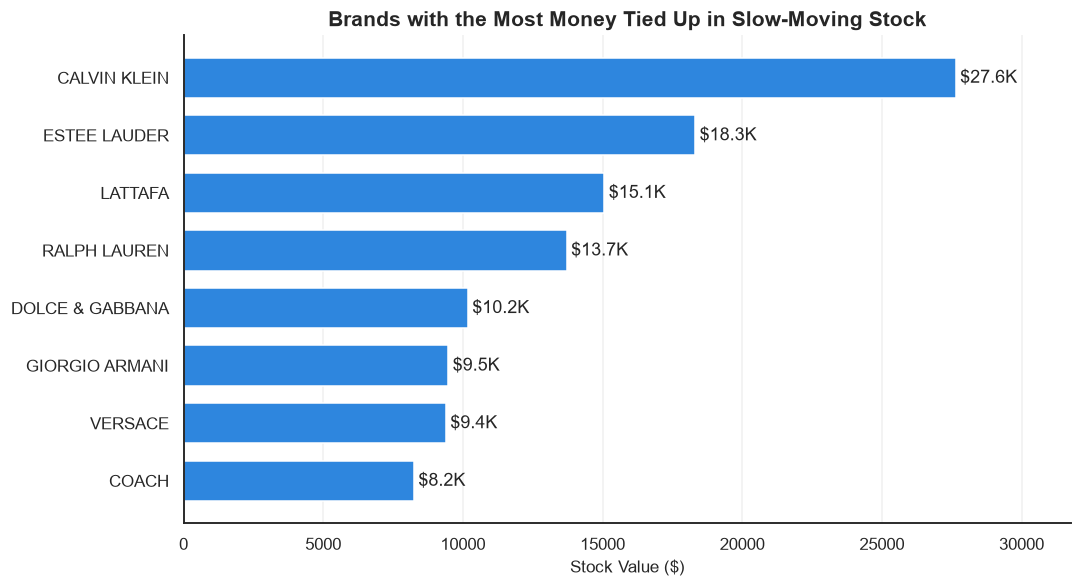

In [242]:
slow_by_brand = (slow[slow['Brand'] != 'UNKNOWN']
                 .groupby('Brand')['Stock_Value'].sum()
                 .sort_values(ascending=False).head(8))

plt.figure(figsize=(10, 5.5))
bars = plt.barh(slow_by_brand.index[::-1], slow_by_brand.values[::-1], color=BLUE_5, height=0.7)
plt.bar_label(bars, labels=[f'${v/1e3:,.1f}K' for v in slow_by_brand.values[::-1]], padding=3)

plt.title('Brands with the Most Money Tied Up in Slow-Moving Stock')
plt.xlabel('Stock Value ($)')
plt.xlim(0, slow_by_brand.max() * 1.15)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Result:** 384 products have slow stock turnover, with about **$279K in retail-value stock**.

- 41 products have high stock, representing about $147K of retail value.
- 343 products have medium stock, representing about $132K.

The single biggest item is Calvin Klein Eternity for Men, with 842 units available and about $26K in retail value.


**Action:** Consider markdowns or bundles for the 41 high-stock products, starting with the highest-stock or highest-value items.

For the 343 medium-stock products, avoid placing new orders until existing stock has had more time to sell, unless there is a clear business reason to reorder.

Because the estimate uses retail price rather than purchase cost, the actual cash tied up in inventory cannot be calculated from this dataset.


## Conclusion

The analysis identifies **better inventory allocation as a key focus area**. 
Nearly half of the total revenue comes from products that are **fast-selling but currently low in stock**, while approximately **$279K in retail-value stock** is tied to slow-moving products.

The findings also show that **Budget and Mid-Range products make up most of the catalogue**, while **Premium products generate the highest average revenue**. Price alone does not determine sales performance, and a relatively small group of brands contributes a significant share of total revenue.

The key focus is to **protect high-performing products, restock proven sellers, reduce slow-moving inventory, and use brand-level performance to guide purchasing and inventory decisions**.

# Recommendations

### 1. Restock Fast-Selling Products First

Prioritise products that are selling quickly and are already low or out of stock. Confirm that zero-stock products are still active before reordering.

### 2. Protect the Strongest Brands

The top 30 brands, about 9% of named brands, generate 73.8% of revenue. Give their best-performing products close attention when planning stock and product availability.

### 3. Review Slow-Moving Stock

About **$279K in retail-value stock** is linked to slow-moving products. Consider markdowns or bundles for high-stock products and avoid unnecessary reordering of medium-stock products.

### 3. Maintain a Strong Budget and Mid-Range Mix

Budget and Mid-Range products make up about 90% of the catalogue and account for a large share of units sold. Maintain a strong selection in these categories while using Premium and Luxury products to serve higher-price demand.

### 5. Do Not Rely on Brand Popularity Alone

Popular brands do not automatically have the highest-performing products. Product-level sales, revenue and inventory should also be considered when making decisions.

### 7. Investigate the Men's Revenue Advantage

Men's and women's catalogues are almost the same size, but men's products generate 65.0% of revenue. A small group of men's brands explains much of the gap, so these brands and products should be examined to understand what is driving their stronger performance.

### 8. Validate the Geographic Data

The United States accounts for almost all of the revenue in the dataset. The geographic distribution should be validated before making decisions based on country performance.

### 7. Do Not Treat Any Single Price Point as a Rule

Products priced up to about $40 sell steadily, while units sold decline above that level. The $19-$30 range has the highest average revenue per product ($28.8K), but this result depends on a small number of best-sellers, with 11 of the top 20 products in this band. Price should therefore be used as a guide alongside brand strength and product demand rather than as a fixed rule.
